# Does a wider mean-centring window help a fill template at K = 10? -- W = 51 / 61 / 71, 49 ROIs x 6 clicks, post-D11

## What this sweep manipulates

For a fill template that equals `t_i` on a keep set of `k` pixels and a constant `f_W` elsewhere,
`cv2.matchTemplate(..., TM_CCOEFF)` reduces exactly to

```
R_W(p) = sum_keep (t_i - f_W)(I_i - mu_W(p))
       = sum_keep (t_i - m_k) I_i  +  (m_k - f_W) k (mu_keep(p) - mu_W(p))
```

`mu_W(p)` is the plain box mean of the image over the W x W window and `m_k` is the template mean over the keep region.
**The first term does not depend on W.** Widening the window therefore does not add "flattened surround": the filled
pixels enter only through the scalar `f_W` and through the width of the box `mu_W` is averaged over. This run
manipulates the **mean-centring window**. It is not a ring-width or dose manipulation.

## The seven arms

A 3 x 2 factorial plus one mechanism probe. For `W in {51, 61, 71}` a `W x W` `hematoxylin_od` window is cut centred on
the click with `tm.read_padded_patch`.

| arm | template |
|---|---|
| `default_W` | the window, untouched |
| `fill_W` | the pixels inside the recorded Otsu rectangle kept; every other pixel set to the mean of those other pixels, **recomputed on this W** |
| `fill_71_pinned` | as `fill_71`, but the fill value pinned to `fill_51`'s `f_51`, so the mass weight `m_k - f` is held exactly |

The keep region is **frozen**: the 51-window-local rectangle `rect_y0:rect_y1, rect_x0:rect_x1` recorded in the
fill-geometry run's clicks CSV, shifted by `off = (W - 51) // 2`. `ss.tighten_box_otsu` is never called and no click is
redrawn. `fill_71_pinned` differs from `fill_51` **only** through `mu_W`, and from `fill_71` **only** through `f_W`.

7 arms x 294 clicks = 2058 searches. Both ranking axes (`tm_score` -> `score`, `chromatin_od` -> `od`) sort the one
detection list each search returns.

## Held identical across arms

- the 294 clicks (49 ROIs x 6) and the Otsu rectangle, read from `precision_at_k_49roi_6seed_fillgeom_postD11_clicks.csv`;
- the blanked square: **51 x 51 for every arm**, `tm.blank_seed_square(hem, cx, cy, 51)`, filled with `channel.min()`;
- `TM_CCOEFF`, `PEAK_MIN_DISTANCE` 7, `DEEP_FLOOR_Z` -1.5 (inert: `MAX_PEAKS` binds), `MAX_PEAKS` 100, NMS radius = match
  radius = `ev.radius_px(mpp)` (7.5 um);
- the `chromatin_od` window (51 px), scored against the **unblanked** channel. The search channel and the `od` channel are
  replicate-padded by `PAD = (W - 1) // 2` (25 / 30 / 35); a 51 px `od` window at any in-ROI detection reaches at most 25 px
  past the edge, so `od` is identical for every pad by construction;
- greedy centre-distance matching at 7.5 um, with the click's own annotation removed from the ground truth.

## Correctness -- one gate, four inline asserts, two diagnostics

**The gate: W = 51 parity.** `default_51` and `fill_51` must reproduce the recorded fill-geometry run (`default_51` and
`hem_rect_fill`) row for row on **both** axes, on all 294 clicks, asserted inline so the run halts on the first mismatch:
`n_peaks`, `n_detections`, `n_blanked_px`, `n_kept_px`, `n_filled_px`, `fill_value` (float32), `tpl_sha1`,
`tp_at_10/20/30`, and top-30 `rank, cx, cy, bucket, matched_ann_id`; `score` after a float32 cast, `od` at `rtol = 1e-12`.

**Inline asserts**, each catching a bug parity cannot see because parity covers only W = 51:

1. `n_blanked_px == 2601` on every row of every arm.
2. `n_filled_px == W*W - n_kept_px`, and the fill value equals `np.float32(T_W[~mask].astype(np.float64).mean())` recomputed
   from the raw window inside the assert (for `fill_71_pinned`: that mean on the 51 window). Without it, a `fill_61`/`fill_71`
   that silently reused `f_51` would turn the run into `fill_W_pinned`.
3. The W-local keep mask cropped to its central 51 x 51 equals the 51-local mask and keeps nothing outside it; and the W
   window's central 51 x 51 equals the 51 window, pixel for pixel (a wrong template offset).
4. `n_detections >= 10`.

**Diagnostics, reported and never halting.** Both definitions were fixed before the run.

- **Near-seed.** The blank is filled with `channel.min()`, which lowers `mu_W` and so *inflates* `R` for tissue in the window.
  The window overlaps the blank out to 50 / 55 / 60 px at W = 51 / 61 / 71. Counted per (arm, axis): top-10 detections
  within 60 px of the click that are **not** true positives, under both **Chebyshev** distance (the square in which a W = 71
  window overlaps the blank, 25 + 35) and **Euclidean** distance (the literal "within 60 px"). The recorded W = 51 run has 0 on
  both, printed below. **A rise above 0 under either definition on a wide arm makes every `fill_61`/`fill_71` gain on that
  axis unresolved.** It is not netted out.
- **ROI edge.** `tp_at_10_excl_border`: every detection with edge distance `min(cx, cy, w-1-cx, h-1-cy) < 35`, the band in
  which a W = 71 template overlaps replicate padding, is dropped from the ranked list, identically in every arm. The rest is
  matched afresh against the same, untouched ground truth, and TP is counted in its top 10. `< 35` is the definition that
  reproduces the recorded 4.70% of top-10 slots. No extra search. It does not touch the primary numbers.

`MAX_PEAKS` binding and NMS suppression (`n_peaks - n_detections`) are recorded per row and reported per arm.

## Statistics, fixed before the run

The unit is the **ROI (49)**. A ROI's value is its TP@10 summed over its 6 clicks (out of 60); pooled precision has
denominator 6 x 49 x 10 = 2940. Per contrast: the pooled delta in points, a 95% cluster-bootstrap CI over ROIs
(`N_BOOT` 10000, `BOOT_SEED` 20260917, the ROI order of the fill-geometry per-run CSV), a t interval over ROI deltas,
ROI W/L/T, `n_nonzero`, an exact sign-flip p by convolution, `min_attainable_p = 2 ** (1 - n_nonzero)`, Holm within family,
and the D5 bar (CI excludes 0 **and** more than 24 of 49 ROIs move in the delta's direction).

**Four Holm families, 8 tests, all at K = 10:**

| family | tests |
|---|---|
| `tm_score \| window` | `fill_61 - fill_51`, `fill_71 - fill_51` |
| `tm_score \| fill_vs_raw` | `(fill_61 - fill_51) - (default_61 - default_51)`, the same at 71 |
| `chromatin_od \| window` | `fill_61 - fill_51`, `fill_71 - fill_51` |
| `chromatin_od \| fill_vs_raw` | the two difference-in-differences |

The difference-in-differences answers Q2. It is computed per ROI from the four per-ROI sums, never by comparing two
separately tested effects. The two axes are **two outcomes**: a result on one is not a replication of the other, and
they are never pooled.

**Descriptive, in no family, supporting no verdict:** `default_W - default_51`; `fill_71_pinned - fill_71` and
`fill_71_pinned - fill_51` (Q4); `fill_W - default_W`; the tested contrasts on `tp_at_10_excl_border` and at K = 20 / 30;
the axis comparison; Q3.

**Q3 is descriptive and bounded.** The keep region is frozen, so 51 -> 71 adds exactly +10 px to every click. A flat
association with nucleus size fits "one window fits all" and "size matters but is locally linear here" equally well. This
design cannot separate those and cannot locate a saturation point from three window values.

**Not done:** no domain analysis (n = 7 per domain puts the Holm floor across 7 domains at 0.109 > 0.05), no K = 20 / 30 in
any verdict, no W > 73, no blank that follows W.

The smoke mode (`WINDOW_SWEEP_SMOKE_ROIS=337.tiff,509.tiff` in the environment) runs the identical code on a subset and writes
`_smoke`-suffixed outputs. The recorded run has it unset.

In [1]:
import gc
import hashlib
import itertools
import math
import os
import sys
import time
from fractions import Fraction

import cv2
import numpy as np
import pandas as pd
from scipy import stats as sps
import matplotlib.pyplot as plt

sys.path.insert(0, '..')
from midog_utils import channels as ch
from midog_utils import chromatin as cm
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import invariants as inv
from midog_utils import production as prod
from midog_utils import template_match as tm
from midog_utils.nms import nms_by_distance

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 140)

NB_T0 = time.time()

REFERENCE_CONFIG = dict(CHANNEL='hematoxylin_od', TM_METHOD=cv2.TM_CCOEFF, PEAK_MIN_DISTANCE=7, DEEP_FLOOR_Z=-1.5, MAX_PEAKS=100, OD_WINDOW=51)
CONFIG_DRIFT = pd.DataFrame([dict(setting=k, production_py=getattr(prod, k), reference_notebook=v, match=getattr(prod, k) == v) for k, v in REFERENCE_CONFIG.items()])
print(CONFIG_DRIFT.to_string(index=False))
assert CONFIG_DRIFT['match'].all(), 'midog_utils.production no longer matches the configuration the recorded run used'
assert cv2.TM_CCOEFF == 4, 'TM_METHOD 4 is cv2.TM_CCOEFF'
assert ev.MIDOG_RADIUS_UM == 7.5, 'D7: NMS radius = match radius = 7.5 um'
assert (tm.BASE_SIZE, tm.PATCH_SIZE) == (51, 73), 'the template and patch sizes this notebook hard-codes'
assert hasattr(tm, 'blank_seed_square') and not hasattr(prod, 'SELF_HIT_RADIUS'), 'this is not post-D11 code'
assert set(prod.AXES) == {'tm_score', 'chromatin_od'}, f'production.AXES changed: {prod.AXES}'

SMOKE_ROIS = [s for s in os.environ.get('WINDOW_SWEEP_SMOKE_ROIS', '').split(',') if s] or None   # None = all 49 ROIs
BASE_SIZE = tm.BASE_SIZE       # 51: the recorded rectangle's frame and the od window
BLANK_SIZE = 51                # the blanked square, for every arm -- never follows W
WINDOWS = (51, 61, 71)
MAX_WINDOW = 2 * (tm.PATCH_SIZE // 2) + 1   # 73: BORDER = PATCH_SIZE // 2 = 36 keeps a 73 px window inside every ROI
assert max(WINDOWS) <= MAX_WINDOW and all(W % 2 == 1 for W in WINDOWS), f'windows {WINDOWS} must be odd and at most {MAX_WINDOW}'
PADS = {W: (W - 1) // 2 for W in WINDOWS}   # 25 / 30 / 35

ARMS = ('default_51', 'fill_51', 'default_61', 'fill_61', 'default_71', 'fill_71', 'fill_71_pinned')
ARM_W = {arm: int(arm.split('_')[1]) for arm in ARMS}
ARM_RULE = {arm: ('the window, untouched' if arm.startswith('default') else ('Otsu rect kept, fill = f_51' if arm.endswith('pinned') else 'Otsu rect kept, fill = mean outside on this W')) for arm in ARMS}
FILL_ARMS = tuple(a for a in ARMS if a.startswith('fill'))
REF_CONDITION = {'default_51': 'default_51', 'fill_51': 'hem_rect_fill'}   # the W = 51 parity targets in the recorded run
AXES = ('chromatin_od', 'tm_score')
AXIS_KEY = {'chromatin_od': 'od', 'tm_score': 'score'}
assert AXIS_KEY == prod.AXES, f'this notebook and production.AXES disagree: {AXIS_KEY} vs {prod.AXES}'

BUDGETS = (10, 20, 30)         # recorded; only TEST_K is ever tested
TEST_K = 10
SEED_INDICES = (0, 1, 2, 3, 4, 5)
N_CLICKS_PER_ROI = len(SEED_INDICES)
N_BOOT = 10_000
BOOT_SEED = 20260917
NEAR_SEED_PX = 60              # BLANK_SIZE // 2 + PADS[71]: how far a W = 71 window reaches into the blank
EDGE_BAND_PX = 35              # PADS[71]: a detection closer than this to an ROI edge has a W = 71 template on replicate padding
assert NEAR_SEED_PX == BLANK_SIZE // 2 + PADS[max(WINDOWS)] and EDGE_BAND_PX == PADS[max(WINDOWS)]

# every contrast is a signed sum of arms; the per-ROI value is that sum of click-summed TP counts, an exact integer
CONTRASTS = {
    'fill_61 - fill_51': {'fill_61': 1, 'fill_51': -1},
    'fill_71 - fill_51': {'fill_71': 1, 'fill_51': -1},
    '(fill_61 - fill_51) - (default_61 - default_51)': {'fill_61': 1, 'fill_51': -1, 'default_61': -1, 'default_51': 1},
    '(fill_71 - fill_51) - (default_71 - default_51)': {'fill_71': 1, 'fill_51': -1, 'default_71': -1, 'default_51': 1},
    'default_61 - default_51': {'default_61': 1, 'default_51': -1},
    'default_71 - default_51': {'default_71': 1, 'default_51': -1},
    'fill_71_pinned - fill_71': {'fill_71_pinned': 1, 'fill_71': -1},
    'fill_71_pinned - fill_51': {'fill_71_pinned': 1, 'fill_51': -1},
    'fill_51 - default_51': {'fill_51': 1, 'default_51': -1},
    'fill_61 - default_61': {'fill_61': 1, 'default_61': -1},
    'fill_71 - default_71': {'fill_71': 1, 'default_71': -1},
}
TEST_FAMILY = {'fill_61 - fill_51': 'window', 'fill_71 - fill_51': 'window', '(fill_61 - fill_51) - (default_61 - default_51)': 'fill_vs_raw', '(fill_71 - fill_51) - (default_71 - default_51)': 'fill_vs_raw'}
TESTED = tuple(TEST_FAMILY)
assert all(sum(c.values()) == 0 for c in CONTRASTS.values()) and set(TESTED) <= set(CONTRASTS), 'a contrast is not a difference, or a tested contrast is undefined'
METRICS = {'tp_at_10': 10, 'tp_at_10_excl_border': 10, 'tp_at_20': 20, 'tp_at_30': 30}   # only tp_at_10 is tested

SRC = '../results/precision_at_k_49roi_6seed_fillgeom_postD11'
SUBSET_DIRS = {'original_14': '../images/extra_valid', 'testing_35': '../images/extra_valid/testing_set'}
SUFFIX = '' if SMOKE_ROIS is None else '_smoke'
OUT_STEM = f'../results/precision_at_k_49roi_6seed_windowsweep_postD11{SUFFIX}'
OUT = {name: f'{OUT_STEM}_{name}.csv' for name in ('per_run', 'per_roi', 'delta_per_roi', 'delta_stats', 'top30')}
FIG_PATHS = {name: f'windowsweep_{name}{SUFFIX}.png' for name in ('contrasts', 'size')}
assert not any(p.startswith(SRC) for p in OUT.values()), 'an output path would overwrite the recorded run'

print(f'\narms {ARMS}; windows {WINDOWS} (pads {PADS}); blank {BLANK_SIZE} px for every arm; axes {AXES}; K tested {TEST_K} only')
print(f'tested ({len(TESTED)} per axis, {2 * len(TESTED)} total): {TESTED}')
print(f'smoke ROIs = {SMOKE_ROIS}')
print('outputs:', *OUT.values(), *FIG_PATHS.values(), sep='\n  ')

          setting  production_py reference_notebook  match
          CHANNEL hematoxylin_od     hematoxylin_od   True
        TM_METHOD              4                  4   True
PEAK_MIN_DISTANCE              7                  7   True
     DEEP_FLOOR_Z           -1.5               -1.5   True
        MAX_PEAKS            100                100   True
        OD_WINDOW             51                 51   True

arms ('default_51', 'fill_51', 'default_61', 'fill_61', 'default_71', 'fill_71', 'fill_71_pinned'); windows (51, 61, 71) (pads {51: 25, 61: 30, 71: 35}); blank 51 px for every arm; axes ('chromatin_od', 'tm_score'); K tested 10 only
tested (4 per axis, 8 total): ('fill_61 - fill_51', 'fill_71 - fill_51', '(fill_61 - fill_51) - (default_61 - default_51)', '(fill_71 - fill_51) - (default_71 - default_51)')
smoke ROIs = None
outputs:
  ../results/precision_at_k_49roi_6seed_windowsweep_postD11_per_run.csv
  ../results/precision_at_k_49roi_6seed_windowsweep_postD11_per_roi.csv
  ../re

In [2]:
CLICKS = pd.read_csv(f'{SRC}_clicks.csv', float_precision='round_trip')
REF_RUN = pd.read_csv(f'{SRC}_per_run.csv', float_precision='round_trip')
REF_TOP = pd.read_csv(f'{SRC}_top30.csv', float_precision='round_trip')
REF_STATS = pd.read_csv(f'{SRC}_delta_stats.csv', float_precision='round_trip')
assert (len(CLICKS), len(REF_RUN), len(REF_TOP), len(REF_STATS)) == (294, 2352, 70560, 10), 'a recorded input does not have its expected row count'
assert not CLICKS.duplicated(['file_name', 'seed_index']).any() and CLICKS.groupby('file_name')['seed_index'].apply(lambda v: tuple(sorted(v)) == SEED_INDICES).all(), 'the clicks CSV is not 6 distinct seeds per ROI'
for c in ('rect_y0', 'rect_y1', 'rect_x0', 'rect_x1'):
    assert CLICKS[c].between(0, BASE_SIZE).all(), f'{c} leaves the 51 px frame'
assert ((CLICKS['rect_y1'] > CLICKS['rect_y0']) & (CLICKS['rect_x1'] > CLICKS['rect_x0'])).all() and (CLICKS['rect_h'] == CLICKS['rect_y1'] - CLICKS['rect_y0']).all() and (CLICKS['rect_w'] == CLICKS['rect_x1'] - CLICKS['rect_x0']).all(), 'a recorded rectangle is empty or inconsistent'

ROI_ORDER_ALL = list(pd.unique(REF_RUN['file_name']))   # the bootstrap's ROI order: the recorded CIs reproduce only in this order
assert len(ROI_ORDER_ALL) == 49 and set(ROI_ORDER_ALL) == set(CLICKS['file_name']), 'the recorded run is not the 49 ROIs of the clicks CSV'
ROI_ORDER = ROI_ORDER_ALL if SMOKE_ROIS is None else [f for f in ROI_ORDER_ALL if f in SMOKE_ROIS]
assert SMOKE_ROIS is None or sorted(ROI_ORDER) == sorted(SMOKE_ROIS), f'smoke ROIs not found: {SMOKE_ROIS}'
N_ROIS = len(ROI_ORDER)

# the W = 51 parity references, keyed with rank_key so the two axes cannot duplicate
REF_RUN_IX, REF_TOP_IX = {}, {}
for arm, cond in REF_CONDITION.items():
    REF_RUN_IX[arm] = REF_RUN[REF_RUN['condition'] == cond].set_index(['file_name', 'seed_index', 'rank_key']).sort_index()
    REF_TOP_IX[arm] = {key: g.sort_values('rank') for key, g in REF_TOP[REF_TOP['condition'] == cond].groupby(['file_name', 'seed_index', 'rank_key'])}
    assert REF_RUN_IX[arm].index.is_unique and len(REF_RUN_IX[arm]) == 588 and len(REF_TOP_IX[arm]) == 588, f'{arm}: the reference is not one row and one top-30 list per (click, axis)'
    assert all(len(g) == 30 and (g['rank'].to_numpy() == np.arange(30)).all() for g in REF_TOP_IX[arm].values()), f'{arm}: a recorded top-30 list is not ranks 0..29'

images, annotations = ds.load_annotations('../databases/MIDOG++.json')
ROI_SIZE = images.set_index('file_name')[['width', 'height']]

# the recorded run's own diagnostic baselines, recomputed here so every quoted number is printed by this notebook
rec = REF_TOP[REF_TOP['rank'] < TEST_K].merge(CLICKS[['file_name', 'seed_index', 'click_cx', 'click_cy']], on=['file_name', 'seed_index']).join(ROI_SIZE, on='file_name')
rec_tp = rec['bucket'] == ev.HUMAN_CORRECT_LABEL
rec_dx, rec_dy = (rec['cx'] - rec['click_cx']).abs(), (rec['cy'] - rec['click_cy']).abs()
rec_edge = np.minimum.reduce([rec['cx'], rec['cy'], rec['width'] - 1 - rec['cx'], rec['height'] - 1 - rec['cy']])
print(f'recorded fill-geometry run, top-{TEST_K} slots over its 4 arms x 2 axes ({len(rec)} slots):')
for name, near in (('Chebyshev', np.maximum(rec_dx, rec_dy) <= NEAR_SEED_PX), ('Euclidean', np.hypot(rec_dx, rec_dy) <= NEAR_SEED_PX)):
    print(f'  near-seed ({name} <= {NEAR_SEED_PX} px): {int(near.sum())} slots, of which not a true positive: {int((near & ~rec_tp).sum())}')
for band_px in (25, EDGE_BAND_PX):
    band = rec_edge < band_px
    print(f'  edge distance < {band_px} px: {100 * band.mean():.2f}% of slots; TP rate in the band {rec_tp[band].mean():.3f}, outside {rec_tp[~band].mean():.3f}')
print(f"  MAX_PEAKS binds on {int(REF_RUN['max_peaks_binding'].sum())}/{len(REF_RUN)} recorded rows")
print(f'\n{N_ROIS} ROIs x {N_CLICKS_PER_ROI} clicks x {len(ARMS)} arms = {N_ROIS * N_CLICKS_PER_ROI * len(ARMS)} searches')

recorded fill-geometry run, top-10 slots over its 4 arms x 2 axes (23520 slots):
  near-seed (Chebyshev <= 60 px): 28 slots, of which not a true positive: 0
  near-seed (Euclidean <= 60 px): 16 slots, of which not a true positive: 0
  edge distance < 25 px: 3.68% of slots; TP rate in the band 0.113, outside 0.562
  edge distance < 35 px: 4.70% of slots; TP rate in the band 0.246, outside 0.560
  MAX_PEAKS binds on 2352/2352 recorded rows

49 ROIs x 6 clicks x 7 arms = 2058 searches


## Statistics, validated before any search runs

The functions are the fill-geometry run's own. Before a single search, they recompute that run's 10 recorded
`delta_stats` rows from its per-run CSV and must match every column. A match proves the ROI aggregation, the ROI order and
the `BOOT_SEED` usage. The bootstrap index for that check is always built over all 49 ROIs, smoke run or not.

In [3]:
def sign_flip_null_counts(abs_deltas):
    """
        Exact null distribution of sum(+/-|d_i|) by convolution over integer offsets.

        abs_deltas (array-like): nonzero absolute integer deltas, one per ROI.

        Returns np.ndarray: int64 counts of each sum -T..T (index = sum + T, T = sum |d_i|), totalling 2 ** n.
    """
    d = [int(v) for v in abs_deltas]
    assert all(v > 0 for v in d) and len(d) <= 62, 'nonzero integer deltas only, and 2 ** n must fit int64'
    total = sum(d)
    counts = np.zeros(2 * total + 1, dtype=np.int64)
    counts[total] = 1
    for v in d:
        shifted = np.zeros_like(counts)
        shifted[v:] += counts[:len(counts) - v]
        shifted[:len(counts) - v] += counts[v:]
        counts = shifted
    return counts


def exact_sign_flip_p(deltas):
    """
        Two-sided exact sign-flip p on integer per-ROI deltas, by dynamic-programming convolution.

        deltas (array-like): one integer delta per ROI; zeros carry no sign.

        Returns tuple[float, int]: the p-value and the number of nonzero deltas.
    """
    d = np.asarray(deltas)
    assert np.all(d == np.round(d)), 'the convolution needs integer deltas'
    d = d.astype(np.int64)
    nz = np.abs(d[d != 0])
    if len(nz) == 0:
        return 1.0, 0
    counts = sign_flip_null_counts(nz)
    total = int(nz.sum())
    observed = abs(int(d.sum()))
    sums = np.arange(-total, total + 1)
    return float(Fraction(int(counts[np.abs(sums) >= observed].sum()), 2 ** len(nz))), len(nz)


def brute_force_sign_flip_p(deltas):
    """
        Two-sided sign-flip p by enumerating every sign pattern -- kept only to validate the convolution.

        deltas (array-like): one delta per ROI; zeros carry no sign and are dropped.

        Returns float: the p-value.
    """
    d = np.asarray(deltas, dtype=np.float64)
    nz = np.abs(d[np.abs(d) > 1e-12])
    if len(nz) == 0:
        return 1.0
    signs = np.array(list(itertools.product([1.0, -1.0], repeat=len(nz))))
    return float((np.abs(signs @ nz) >= abs(float(d.sum())) - 1e-9).mean())


def holm_adjust(pvalues):
    """
        Holm step-down adjusted p-values, valid under any dependence between the tests.

        pvalues (array-like): raw p-values of one family of tests.

        Returns np.ndarray: adjusted p-values, in the input order.
    """
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p, kind='stable')
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1.0)
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out


def boot_index(n_roi, stream=0):
    """
        The cluster-bootstrap resample of ROI indices, seeded exactly as every earlier run seeds it.

        n_roi (int): the number of ROIs being resampled.
        stream (int): 0 for the reported CI; 1.. for the re-seeding stability check.

        Returns np.ndarray: (N_BOOT, n_roi) resampled ROI indices.
    """
    return np.random.default_rng([BOOT_SEED, stream]).integers(n_roi, size=(N_BOOT, n_roi))


def boot_ci_exact(int_values, idx, denominator):
    """
        Percentile 95% CI of a pooled ratio over resampled ROIs, from exact integer numerators.

        int_values (np.ndarray): one integer numerator per ROI.
        idx (np.ndarray): (n_boot, n_roi) resampled ROI indices.
        denominator (int): the pooled denominator per resample.

        Returns tuple[float, float, float, float]: CI low, CI high, and the share of resamples at or above 0 and at or below 0.
    """
    sums = np.asarray(int_values, dtype=np.int64)[idx].sum(axis=1)
    lo, hi = np.percentile(sums / denominator, [2.5, 97.5])
    return float(lo), float(hi), float((sums >= 0).mean()), float((sums <= 0).mean())


def pair_stats(d, k, idx):
    """
        Every statistic for one contrast at one budget, from its per-ROI click-summed integer deltas.

        d (np.ndarray): one integer delta per ROI, in ROI order.
        k (int): the budget K the deltas count true positives in.
        idx (np.ndarray): (N_BOOT, len(d)) bootstrap ROI indices.

        Returns dict: one delta_stats row without its Holm columns.
    """
    d = np.asarray(d, dtype=np.int64)
    n_roi = len(d)
    denominator = N_CLICKS_PER_ROI * n_roi * k
    pooled = d.sum() / denominator
    wins, losses, ties = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    exact_p, n_nonzero = exact_sign_flip_p(d)
    ci_low, ci_high, share_ge_0, share_le_0 = boot_ci_exact(d, idx, denominator)
    x = d / (N_CLICKS_PER_ROI * k)
    half = sps.t.ppf(0.975, n_roi - 1) * x.std(ddof=1) / math.sqrt(n_roi) if n_roi > 1 else np.nan
    t_ci_low, t_ci_high = float(x.mean() - half), float(x.mean() + half)
    ci_excludes_0 = bool(ci_low > 0 or ci_high < 0)
    n_same_direction = wins if pooled > 0 else (losses if pooled < 0 else 0)
    majority = bool(n_same_direction > n_roi / 2)
    return dict(n_roi=n_roi, n_clicks=N_CLICKS_PER_ROI * n_roi, pooled_delta_precision=pooled, wins=wins, losses=losses, ties=ties, n_nonzero=n_nonzero, exact_p=exact_p, min_attainable_p=2.0 ** (1 - n_nonzero) if n_nonzero else 1.0, ci_low=ci_low, ci_high=ci_high, boot_share_ge_0=share_ge_0, boot_share_le_0=share_le_0, t_ci_low=t_ci_low, t_ci_high=t_ci_high, ci_excludes_0=ci_excludes_0, t_ci_excludes_0=bool(t_ci_low > 0 or t_ci_high < 0), n_same_direction=n_same_direction, majority_of_all_rois=majority, d5_bar_met=bool(ci_excludes_0 and majority))


check_rng = np.random.default_rng(0)
for n in range(1, 13):
    for _ in range(20):
        v = check_rng.integers(-6, 7, size=n)
        assert exact_sign_flip_p(v)[0] == brute_force_sign_flip_p(v), f'convolution != enumeration on {v}'
print('convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)')

# the fill-geometry run's 10 recorded delta_stats rows, recomputed from its per-run CSV with these functions over all 49 ROIs
ref_roi = REF_RUN.groupby(['rank_key', 'condition', 'file_name'])['tp_at_10'].sum()
idx49 = boot_index(len(ROI_ORDER_ALL))
recomputed = []
for r in REF_STATS.itertuples():
    a, b = r.pair.split(' - ')
    d = np.array([ref_roi[(r.rank_key, a, f)] - ref_roi[(r.rank_key, b, f)] for f in ROI_ORDER_ALL])
    recomputed.append(dict(rank_key=r.rank_key, pair=r.pair, holm_family=r.holm_family, **pair_stats(d, int(r.K), idx49)))
recomputed = pd.DataFrame(recomputed)
recomputed['holm_p'] = recomputed.groupby('holm_family')['exact_p'].transform(lambda p: holm_adjust(p.to_numpy()))
for c in ('wins', 'losses', 'ties', 'n_nonzero', 'n_same_direction', 'ci_excludes_0', 'majority_of_all_rois', 'd5_bar_met'):
    assert (recomputed[c].to_numpy() == REF_STATS[c].to_numpy()).all(), f'stats validation: {c} differs from the recorded delta_stats'
for c in ('pooled_delta_precision', 'exact_p', 'min_attainable_p', 'ci_low', 'ci_high', 't_ci_low', 't_ci_high', 'holm_p'):
    assert np.allclose(recomputed[c].to_numpy(), REF_STATS[c].to_numpy(), rtol=1e-12, atol=0), f'stats validation: {c} differs from the recorded delta_stats'
print(f'stats validation passed: all {len(REF_STATS)} recorded fill-geometry delta_stats rows reproduce column for column (ROI order, BOOT_SEED, Holm families)')
print(recomputed[['rank_key', 'pair', 'pooled_delta_precision', 'ci_low', 'ci_high', 'exact_p', 'holm_p']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)
stats validation passed: all 10 recorded fill-geometry delta_stats rows reproduce column for column (ROI order, BOOT_SEED, Holm families)
    rank_key                                  pair  pooled_delta_precision     ci_low  ci_high  exact_p  holm_p
chromatin_od            hem_rect_fill - default_51                0.001361  -0.005442 0.008844   0.7947  0.9779
chromatin_od        hem_rect_fill_1um - default_51                0.005102  -0.002721  0.01327   0.2503  0.7508
chromatin_od        hem_mask_fill_1um - default_51                0.003061  -0.004082  0.01088    0.489  0.9779
chromatin_od     hem_rect_fill_1um - hem_rect_fill                0.003741 -0.0006803 0.008844   0.1668  0.3336
chromatin_od hem_mask_fill_1um - hem_rect_fill_1um               -0.002041  -0.006122 0.001701   0.4332  0.4332
    tm_score            hem_rect_fill - default_51                 0.01803   0.004762  0.03197  0.01453 0.043

## Templates and the search, inlined once

`build_templates` cuts all three windows for a click and builds the seven templates, each from its own fresh copy of its
window. `search_once` is the fill-geometry run's search generalised to a `W`-sized template: the blanked search channel and the
unblanked `od` channel are padded by `(W - 1) // 2`, so the correlation map covers every ROI pixel and is cropped back. Both
axes then rank the one detection list it returns.

In [4]:
def keep_mask(rect, W):
    """
        The frozen Otsu rectangle as a boolean keep mask in a W-sized window centred on the same click.

        rect (tuple[int, int, int, int]): (y0, y1, x0, x1), half-open, 51-window-local, as recorded.
        W (int): the odd window side.

        Returns np.ndarray: a W x W boolean mask, True inside the shifted rectangle.
    """
    off = (W - BASE_SIZE) // 2
    y0, y1, x0, x1 = rect
    mask = np.zeros((W, W), bool)
    mask[y0 + off:y1 + off, x0 + off:x1 + off] = True
    return mask


def fill_outside(T, keep, fill=None):
    """
        A copy of the template with every pixel outside the keep mask set to one fill value.

        T (np.ndarray): the W x W float32 window.
        keep (np.ndarray): the W x W boolean keep mask.
        fill (np.float32 or None): the fill value; None fills with the mean of the outside pixels on this window.

        Returns tuple[np.ndarray, np.float32, int]: the filled template, the fill value, and the number of filled pixels.
    """
    outside = ~keep
    assert outside.any(), 'the keep region covers the whole window, so there is nothing to fill'
    value = np.float32(T[outside].astype(np.float64).mean()) if fill is None else np.float32(fill)
    F = np.array(T, dtype=np.float32, copy=True)
    F[outside] = value
    return np.ascontiguousarray(F), value, int(outside.sum())


def template_sha1(T):
    """
        SHA-1 of a template's float32 bytes, the digest the recorded run stores as tpl_sha1.

        T (np.ndarray): the float32 template.

        Returns str: the hex digest.
    """
    return hashlib.sha1(np.ascontiguousarray(T, dtype=np.float32).tobytes()).hexdigest()


def build_templates(hem, cx, cy, rect):
    """
        The seven arms' templates for one click, each built from its own fresh copy of its window.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        cx (float): click x, full-image pixels.
        cy (float): click y, full-image pixels.
        rect (tuple[int, int, int, int]): the recorded Otsu rectangle, 51-window-local.

        Returns tuple[dict, dict, dict]: arm -> dict(T, W, fill, n_filled, n_kept), W -> raw window, W -> keep mask.
    """
    windows = {}
    for W in WINDOWS:
        patch = tm.read_padded_patch(hem, cx, cy, W)
        assert patch is not None, f'({cx}, {cy}): the {W} px window is not readable'
        windows[W] = np.array(patch, dtype=np.float32, copy=True)
    keeps = {W: keep_mask(rect, W) for W in WINDOWS}
    arms = {}
    for W in WINDOWS:
        arms[f'default_{W}'] = dict(T=np.array(windows[W], copy=True), W=W, fill=np.float32(np.nan), n_filled=0, n_kept=W * W)
        F, f, n = fill_outside(np.array(windows[W], copy=True), keeps[W])
        arms[f'fill_{W}'] = dict(T=F, W=W, fill=f, n_filled=n, n_kept=int(keeps[W].sum()))
    F, f, n = fill_outside(np.array(windows[71], copy=True), keeps[71], fill=arms['fill_51']['fill'])
    arms['fill_71_pinned'] = dict(T=F, W=71, fill=f, n_filled=n, n_kept=int(keeps[71].sum()))
    assert tuple(arms) == tuple(sorted(arms, key=ARMS.index)) and set(arms) == set(ARMS), 'the arm set changed'
    return arms, windows, keeps


def padded(channel, pad):
    """
        A channel replicate-padded on every side.

        channel (np.ndarray): the channel to pad.
        pad (int): pixels added on every side.

        Returns np.ndarray: the padded channel.
    """
    return cv2.copyMakeBorder(channel, pad, pad, pad, pad, borderType=cv2.BORDER_REPLICATE)


def search_once(search_padded, od_padded, shape, template, pad, nms_radius):
    """
        One template's search over the ROI, stopping before the ranking sort so both axes rank the same detections.

        search_padded (np.ndarray): the D11-blanked search channel, padded by pad.
        od_padded (np.ndarray): the UNBLANKED hematoxylin_od channel, padded by pad, for chromatin_od scoring only.
        shape (tuple): the unpadded channel's (height, width).
        template (np.ndarray): the W x W float32 template, W = 2 * pad + 1.
        pad (int): the replicate pad, (W - 1) // 2.
        nms_radius (float): this ROI's NMS radius in pixels, evaluate.radius_px(mpp).

        Returns tuple[pd.DataFrame, dict]: unranked detections (cx, cy, score, od) and the counts n_peaks, n_detections.
    """
    assert template.shape == (2 * pad + 1, 2 * pad + 1), f'template {template.shape} does not match pad {pad}'
    h, w = shape
    fused_p, _, valid_p = tm.fused_response(search_padded, [template], False, method=prod.TM_METHOD)
    fused = fused_p[pad:pad + h, pad:pad + w]
    valid = valid_p[pad:pad + h, pad:pad + w]
    assert valid.all(), f'the {pad} px pad left part of the ROI unreachable'
    med, mad = tm.robust_stats(fused, valid)
    threshold = med + prod.DEEP_FLOOR_Z * mad
    centers, scores = tm.extract_peaks(fused, valid, prod.PEAK_MIN_DISTANCE, threshold, prod.MAX_PEAKS)
    n_peaks = len(centers)
    keep = nms_by_distance(centers, scores, nms_radius)
    centers, scores = centers[keep], scores[keep]
    det = pd.DataFrame({'rank': np.arange(len(centers)), 'cx': centers[:, 0], 'cy': centers[:, 1], 'score': scores})
    shifted = det.assign(cx=det['cx'] + pad, cy=det['cy'] + pad)
    det = det.assign(od=cm.score_detections(shifted, od_padded, window=prod.OD_WINDOW)['od'].to_numpy())
    return det, {'n_peaks': n_peaks, 'n_detections': len(det)}


def rank_by(det, rank_key):
    """
        One ranking axis applied to a detection list, in run_production_pipeline's own sort order.

        det (pd.DataFrame): the unranked detections from search_once.
        rank_key (str): "chromatin_od" or "tm_score".

        Returns pd.DataFrame: the detections ranked best-first, with rank reassigned.
    """
    out = det.sort_values(AXIS_KEY[rank_key], ascending=False, na_position='last', kind='mergesort').reset_index(drop=True)
    return out.assign(rank=np.arange(len(out)))


def score_top_k(detections, gt_eval, match_radius):
    """
        Match a ranked detection list to ground truth and count true positives in each top-K.

        detections (pd.DataFrame): ranked detections, best first.
        gt_eval (pd.DataFrame): ground truth with the click's own annotation removed.
        match_radius (float): match radius in pixels.

        Returns tuple[pd.DataFrame, dict]: the detections with match buckets added, and K -> true positives in the top K.
    """
    det_out, _ = ev.bucket_detections(detections, gt_eval, match_radius)
    hit = (det_out['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
    return det_out, {k: int(hit[:k].sum()) for k in BUDGETS}


def edge_distance(det, shape):
    """
        Each detection's distance in pixels to the nearest ROI edge.

        det (pd.DataFrame): detections with cx, cy in unpadded ROI pixels.
        shape (tuple): the ROI's (height, width).

        Returns np.ndarray: min(cx, cy, w - 1 - cx, h - 1 - cy) per detection.
    """
    h, w = shape
    return np.minimum.reduce([det['cx'].to_numpy(), det['cy'].to_numpy(), w - 1 - det['cx'].to_numpy(), h - 1 - det['cy'].to_numpy()])


def tp_excl_border(ranked, gt_eval, match_radius, shape):
    """
        True positives in the top TEST_K once every detection in the edge band is dropped and the rest is matched afresh.

        ranked (pd.DataFrame): one axis's ranked detections, before matching.
        gt_eval (pd.DataFrame): ground truth with the click's own annotation removed, untouched.
        match_radius (float): match radius in pixels.
        shape (tuple): the ROI's (height, width).

        Returns tuple[int, int, int]: TP in the kept list's top TEST_K, detections kept, and top-TEST_K slots of the full list inside the band.
    """
    in_band = edge_distance(ranked, shape) < EDGE_BAND_PX
    kept = ranked[~in_band].reset_index(drop=True)
    out, _ = ev.bucket_detections(kept, gt_eval, match_radius)
    return int((out['bucket'].to_numpy()[:TEST_K] == ev.HUMAN_CORRECT_LABEL).sum()), len(kept), int(in_band[:TEST_K].sum())


def near_seed_counts(out, cx, cy):
    """
        Top-TEST_K detections within NEAR_SEED_PX of the click, and how many of them are not true positives.

        out (pd.DataFrame): one axis's ranked, matched detections.
        cx (float): click x.
        cy (float): click y.

        Returns dict: all and non-TP near-seed counts, under Chebyshev and Euclidean distance.
    """
    top = out.head(TEST_K)
    dx, dy = np.abs(top['cx'].to_numpy() - cx), np.abs(top['cy'].to_numpy() - cy)
    not_tp = (top['bucket'] != ev.HUMAN_CORRECT_LABEL).to_numpy()
    cheb, euc = np.maximum(dx, dy) <= NEAR_SEED_PX, np.hypot(dx, dy) <= NEAR_SEED_PX
    return dict(n_near_seed_top10_cheb=int(cheb.sum()), n_near_seed_fp_top10_cheb=int((cheb & not_tp).sum()), n_near_seed_top10_euclid=int(euc.sum()), n_near_seed_fp_top10_euclid=int((euc & not_tp).sum()))


def parity_gate(tag, row, out, ref_run, ref_top):
    """
        Assert that a W = 51 arm reproduces the recorded fill-geometry run, and count the top-30 od values that match bit for bit.

        tag (str): names the click, arm and axis in assertion messages.
        row (dict): this run's per_run row for the click, arm and axis.
        out (pd.DataFrame): this run's ranked, matched detections.
        ref_run (pd.Series): the recorded per_run row.
        ref_top (pd.DataFrame): the recorded top-30 rows, sorted by rank.

        Returns int: the number of top-30 od values equal to the recorded ones bit for bit.
    """
    for c in ('n_peaks', 'n_detections', 'n_blanked_px', 'n_kept_px', 'n_filled_px', 'tp_at_10', 'tp_at_20', 'tp_at_30'):
        assert int(row[c]) == int(ref_run[c]), f'{tag}: {c} {row[c]} != recorded {int(ref_run[c])}'
    assert row['tpl_sha1'] == ref_run['tpl_sha1'], f'{tag}: template SHA-1 differs from the recorded run'
    assert (np.isnan(row['fill_value']) and np.isnan(ref_run['fill_value'])) or np.float32(row['fill_value']) == np.float32(ref_run['fill_value']), f"{tag}: fill {row['fill_value']} != recorded {ref_run['fill_value']}"
    top = out.head(30)
    assert len(top) == len(ref_top) == 30, f'{tag}: {len(top)} rows vs {len(ref_top)} recorded'
    for c in ('rank', 'cx', 'cy', 'bucket', 'matched_ann_id'):
        assert np.array_equal(top[c].to_numpy(), ref_top[c].to_numpy()), f'{tag}: top-30 {c} differs from the recorded list'
    assert np.array_equal(top['score'].to_numpy(), ref_top['score'].to_numpy().astype(np.float32)), f'{tag}: top-30 float32 score differs from the recorded list'
    assert np.isclose(top['od'].to_numpy(), ref_top['od'].to_numpy(), rtol=1e-12, atol=0).all(), f'{tag}: top-30 od differs from the recorded list beyond rtol 1e-12'
    return int((top['od'].to_numpy() == ref_top['od'].to_numpy()).sum())

## The run -- 49 ROIs x 6 clicks x 7 arms, both axes from each search

The W = 51 parity gate and the four asserts fire inline, click by click. The per-run and top-30 CSVs are rewritten after
every ROI, so a crash leaves partial results.

In [5]:
per_run_rows, top_frames, click_rows = [], [], []
n_parity, n_od_bit_exact = 0, 0
t_loop = time.time()
for i, file_name in enumerate(ROI_ORDER):
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    assert os.path.exists(path), f'{path} does not exist'
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f"{file_name}: mpp {mpp!r} != the recorded {rows['mpp'].iat[0]!r}"
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    assert hem.dtype == np.float32 and hem.shape == (ROI_SIZE.loc[file_name, 'height'], ROI_SIZE.loc[file_name, 'width']), f'{file_name}: channel {hem.shape} {hem.dtype}'
    od_padded = {W: padded(hem, PADS[W]) for W in WINDOWS}
    gt = ds.image_annotations(annotations, file_name)
    nms_radius = match_radius = ev.radius_px(mpp)
    inv.check_nms_radius(nms_radius, mpp, label='windowsweep')

    progress = []
    for r in rows.itertuples():
        cx, cy, s = float(r.click_cx), float(r.click_cy), int(r.seed_index)
        tag = f'{file_name} s{s}'
        rect = (int(r.rect_y0), int(r.rect_y1), int(r.rect_x0), int(r.rect_x1))
        arms, windows, keeps = build_templates(hem, cx, cy, rect)

        for W in WINDOWS:
            off = (W - BASE_SIZE) // 2
            # assert 3 -- the W-local keep mask is the 51-local one, shifted; the W window's centre is the 51 window
            assert np.array_equal(keeps[W][off:off + BASE_SIZE, off:off + BASE_SIZE], keeps[BASE_SIZE]) and keeps[W].sum() == keeps[BASE_SIZE].sum() and np.array_equal(windows[W][off:off + BASE_SIZE, off:off + BASE_SIZE], windows[BASE_SIZE]), f'{tag} W={W}: the keep mask or the window is offset'
        f51_recomputed = np.float32(windows[51][~keeps[51]].astype(np.float64).mean())
        for arm in FILL_ARMS:
            a, raw, keep = arms[arm], windows[arms[arm]['W']], keeps[arms[arm]['W']]
            expected = f51_recomputed if arm == 'fill_71_pinned' else np.float32(raw[~keep].astype(np.float64).mean())
            # assert 2 -- filled count, and the fill recomputed here from the raw window rather than read from the construction
            assert a['n_filled'] == a['W'] ** 2 - a['n_kept'] and a['fill'] == expected and (a['T'][~keep] == expected).all() and np.array_equal(a['T'][keep], raw[keep]), f'{tag} {arm}: fill {a["fill"]} != recomputed {expected}, or the template is not keep-or-fill'
        sha = {arm: template_sha1(arms[arm]['T']) for arm in ARMS}
        assert (sha['default_51'], sha['fill_51']) == (r.sha_default_51, r.sha_hem_rect_fill), f'{tag}: a W = 51 template differs from the recorded clicks CSV'

        m_keep = float(windows[51][keeps[51]].astype(np.float64).mean())
        n_kept = int(keeps[51].sum())
        click_rows.append(dict(file_name=file_name, seed_index=s, n_kept_px=n_kept, rect_h=int(r.rect_h), rect_w=int(r.rect_w), m_keep=m_keep, **{f'fill_{W}': float(arms[f'fill_{W}']['fill']) for W in WINDOWS}, **{f'mass_weight_{W}': m_keep - float(arms[f'fill_{W}']['fill']) for W in WINDOWS}, **{f'filled_share_{W}': (W * W - n_kept) / (W * W) for W in WINDOWS}, n_distinct_templates=len(set(sha.values())), pinned_equals_fill_71=sha['fill_71_pinned'] == sha['fill_71']))

        search, n_blanked = tm.blank_seed_square(hem, cx, cy, BLANK_SIZE)
        gt_eval = gt[gt['ann_id'] != r.seed_ann_id].reset_index(drop=True)
        n_gt = int((gt_eval['category_id'] == ds.MITOTIC).sum())
        tp_click = {}
        for W in WINDOWS:
            search_padded = padded(search, PADS[W])
            for arm in [x for x in ARMS if ARM_W[x] == W]:
                a = arms[arm]
                t0 = time.time()
                det, info = search_once(search_padded, od_padded[W], hem.shape, a['T'], PADS[W], nms_radius)
                t_search = time.time() - t0
                assert n_blanked == BLANK_SIZE ** 2, f'{tag} {arm}: {n_blanked} px blanked, not {BLANK_SIZE ** 2}'   # assert 1
                assert info['n_detections'] >= TEST_K, f"{tag} {arm}: {info['n_detections']} detections, fewer than K = {TEST_K}"   # assert 4
                for axis in AXES:
                    ranked = rank_by(det, axis)
                    out, tp = score_top_k(ranked, gt_eval, match_radius)
                    tp_xb, n_kept_xb, n_band_top10 = tp_excl_border(ranked, gt_eval, match_radius, hem.shape)
                    row = dict(subset=r.subset, domain=r.domain, file_name=file_name, image_id=int(r.image_id), seed_index=s, condition=arm, W=W, template_rule=ARM_RULE[arm], rank_key=axis,
                               seed_ann_id=int(r.seed_ann_id), click_cx=cx, click_cy=cy, mpp=mpp, match_radius_px=match_radius, n_gt_mitotic=n_gt, tpl_sha1=sha[arm],
                               n_kept_px=a['n_kept'], n_filled_px=a['n_filled'], fill_value=float(a['fill']), mass_weight=m_keep - float(a['fill']) if arm in FILL_ARMS else np.nan,
                               n_peaks=info['n_peaks'], max_peaks_binding=bool(info['n_peaks'] == prod.MAX_PEAKS), n_detections=info['n_detections'], n_nms_suppressed=info['n_peaks'] - info['n_detections'],
                               n_blanked_px=n_blanked, od_nan=int(out['od'].isna().sum()), t_search_s=round(t_search, 3), **{f'tp_at_{k}': tp[k] for k in BUDGETS},
                               tp_at_10_excl_border=tp_xb, n_detections_excl_border=n_kept_xb, n_border_band_top10=n_band_top10, **near_seed_counts(out, cx, cy), n_od_bit_exact=np.nan)
                    if arm in REF_CONDITION:
                        # the gate -- W = 51 parity with the recorded run, every click, both axes
                        row['n_od_bit_exact'] = parity_gate(f'{tag} {arm} @ {axis}', row, out, REF_RUN_IX[arm].loc[(file_name, s, axis)], REF_TOP_IX[arm][(file_name, s, axis)])
                        n_parity += 1
                        n_od_bit_exact += row['n_od_bit_exact']
                    per_run_rows.append(row)
                    top_frames.append(out.head(30)[['rank', 'cx', 'cy', 'score', 'od', 'bucket', 'matched_ann_id', 'matched_category']].assign(file_name=file_name, seed_index=s, condition=arm, rank_key=axis))
                    tp_click[(arm, axis)] = tp[TEST_K]
            del search_padded
        del search
        progress.append(f's{s} ' + ' '.join(f"{W}:{tp_click[(f'default_{W}', 'tm_score')]}/{tp_click[(f'fill_{W}', 'tm_score')]}" for W in WINDOWS) + f" pin:{tp_click[('fill_71_pinned', 'tm_score')]}")

    pd.DataFrame(per_run_rows).to_csv(OUT['per_run'], index=False)
    pd.concat(top_frames, ignore_index=True).to_csv(OUT['top30'], index=False)
    del hem, od_padded
    gc.collect()
    print(f'[{i + 1}/{N_ROIS} {file_name}] {(time.time() - t_loop) / 60:.1f} min | tm_score TP@{TEST_K} default/fill by W | ' + ' | '.join(progress), flush=True)

PER_RUN = pd.DataFrame(per_run_rows)
TOP = pd.concat(top_frames, ignore_index=True)
TEMPLATES = pd.DataFrame(click_rows)
RUNTIME_LOOP_MIN = (time.time() - t_loop) / 60
assert len(PER_RUN) == N_ROIS * N_CLICKS_PER_ROI * len(ARMS) * len(AXES) and len(TEMPLATES) == N_ROIS * N_CLICKS_PER_ROI, 'the run is not one row per (click, arm, axis)'
print(f'\nthe gate: W = 51 parity held on {n_parity}/{N_ROIS * N_CLICKS_PER_ROI * len(REF_CONDITION) * len(AXES)} (click, arm, axis) rows -- default_51 and fill_51 reproduce the recorded default_51 and hem_rect_fill on both axes')
print(f'  top-30 od bit-exact on {n_od_bit_exact}/{30 * n_parity} rows (the rest within rtol 1e-12)')
print(f'asserts 1-4 held on all {len(PER_RUN) // len(AXES)} searches; per-search time by W (median s): ' + ', '.join(f"{W}: {PER_RUN.loc[PER_RUN['W'] == W, 't_search_s'].median():.2f}" for W in WINDOWS))
print(f'run loop: {RUNTIME_LOOP_MIN:.1f} min for {len(PER_RUN) // len(AXES)} searches ({len(PER_RUN)} rows)')

[1/49 300.tiff] 1.5 min | tm_score TP@10 default/fill by W | s0 51:9/9 61:9/10 71:8/10 pin:10 | s1 51:10/10 61:9/10 71:7/10 pin:10 | s2 51:9/8 61:9/9 71:9/9 pin:8 | s3 51:8/9 61:8/10 71:9/9 pin:9 | s4 51:9/10 61:9/10 71:9/10 pin:10 | s5 51:10/10 61:10/10 71:8/10 pin:10


[2/49 301.tiff] 3.1 min | tm_score TP@10 default/fill by W | s0 51:7/7 61:2/7 71:2/7 pin:5 | s1 51:9/9 61:9/9 71:9/9 pin:9 | s2 51:4/9 61:3/9 71:0/9 pin:9 | s3 51:7/7 61:8/7 71:8/7 pin:7 | s4 51:9/9 61:9/9 71:9/9 pin:9 | s5 51:9/8 61:9/8 71:9/8 pin:8


[3/49 322.tiff] 4.9 min | tm_score TP@10 default/fill by W | s0 51:7/7 61:7/7 71:7/7 pin:7 | s1 51:6/6 61:7/6 71:7/6 pin:6 | s2 51:7/8 61:7/8 71:5/8 pin:8 | s3 51:8/7 61:8/8 71:8/7 pin:7 | s4 51:7/6 61:7/6 71:7/6 pin:6 | s5 51:7/7 61:7/7 71:6/7 pin:7


[4/49 337.tiff] 6.5 min | tm_score TP@10 default/fill by W | s0 51:4/7 61:3/7 71:5/7 pin:6 | s1 51:5/6 61:5/6 71:4/7 pin:7 | s2 51:6/7 61:7/7 71:4/7 pin:7 | s3 51:5/6 61:5/5 71:4/4 pin:5 | s4 51:7/7 61:6/7 71:7/6 pin:6 | s5 51:4/6 61:5/5 71:3/5 pin:5


[5/49 339.tiff] 8.2 min | tm_score TP@10 default/fill by W | s0 51:2/2 61:3/3 71:4/3 pin:3 | s1 51:3/3 61:3/3 71:4/4 pin:4 | s2 51:4/4 61:5/4 71:5/4 pin:4 | s3 51:3/3 61:4/4 71:4/4 pin:4 | s4 51:5/4 61:5/4 71:5/4 pin:4 | s5 51:3/3 61:3/3 71:4/5 pin:5


...

[46/49 364.tiff] 87.3 min | tm_score TP@10 default/fill by W | s0 51:4/4 61:4/4 71:4/4 pin:4 | s1 51:4/4 61:4/4 71:4/4 pin:4 | s2 51:4/3 61:3/3 71:2/3 pin:3 | s3 51:4/4 61:4/4 71:4/5 pin:5 | s4 51:5/5 61:5/5 71:5/5 pin:5 | s5 51:5/3 61:4/3 71:4/3 pin:4


[47/49 400.tiff] 88.7 min | tm_score TP@10 default/fill by W | s0 51:9/9 61:9/9 71:8/9 pin:8 | s1 51:8/8 61:8/7 71:8/7 pin:7 | s2 51:8/8 61:8/8 71:8/8 pin:8 | s3 51:8/7 61:8/9 71:9/9 pin:9 | s4 51:9/9 61:9/9 71:9/9 pin:9 | s5 51:9/9 61:8/8 71:7/8 pin:8


[48/49 401.tiff] 90.2 min | tm_score TP@10 default/fill by W | s0 51:6/6 61:6/6 71:6/6 pin:6 | s1 51:6/6 61:6/6 71:6/6 pin:6 | s2 51:6/6 61:6/6 71:6/6 pin:7 | s3 51:6/6 61:5/5 71:4/5 pin:5 | s4 51:5/5 61:5/5 71:5/6 pin:6 | s5 51:4/5 61:4/5 71:4/5 pin:5


[49/49 404.tiff] 91.7 min | tm_score TP@10 default/fill by W | s0 51:4/4 61:5/4 71:5/5 pin:5 | s1 51:2/2 61:2/2 71:2/2 pin:2 | s2 51:3/3 61:4/3 71:3/3 pin:3 | s3 51:5/4 61:4/5 71:4/4 pin:4 | s4 51:1/1 61:1/1 71:1/2 pin:2 | s5 51:0/0 61:1/1 71:0/2 pin:2



the gate: W = 51 parity held on 1176/1176 (click, arm, axis) rows -- default_51 and fill_51 reproduce the recorded default_51 and hem_rect_fill on both axes
  top-30 od bit-exact on 35280/35280 rows (the rest within rtol 1e-12)
asserts 1-4 held on all 2058 searches; per-search time by W (median s): 51: 2.27, 61: 2.52, 71: 1.96
run loop: 91.7 min for 2058 searches (4116 rows)


## Diagnostics -- reported, never halting

In [6]:
by_arm = PER_RUN.groupby(['condition', 'rank_key'], sort=False)
print('MAX_PEAKS binding and NMS suppression (n_peaks - n_detections), per arm (one search, so identical on both axes):')
nms_tab = PER_RUN[PER_RUN['rank_key'] == AXES[0]].groupby('condition', sort=False).agg(max_peaks_binding=('max_peaks_binding', 'mean'), n_peaks_min=('n_peaks', 'min'), nms_suppressed_mean=('n_nms_suppressed', 'mean'), nms_suppressed_median=('n_nms_suppressed', 'median'), nms_suppressed_min=('n_nms_suppressed', 'min'), nms_suppressed_max=('n_nms_suppressed', 'max'), n_detections_min=('n_detections', 'min'))
print(nms_tab.reindex(ARMS).to_string(float_format=lambda v: f'{v:.3g}'))
print(f"\n[assert 1] blanked pixel counts over every row: {sorted(PER_RUN['n_blanked_px'].unique())}; [assert 4] fewest detections {PER_RUN['n_detections'].min()}; od NaN {int(PER_RUN['od_nan'].sum())}")

NEAR = PER_RUN.groupby(['rank_key', 'condition'], sort=False)[['n_near_seed_top10_cheb', 'n_near_seed_fp_top10_cheb', 'n_near_seed_top10_euclid', 'n_near_seed_fp_top10_euclid']].sum()
print(f'\nnear-seed: top-{TEST_K} detections within {NEAR_SEED_PX} px of the click, and those that are NOT true positives (recorded W = 51 run: 0 not-TP on both definitions):')
print(NEAR.to_string())
wide_fp = NEAR.loc[[(ax, a) for ax in AXES for a in ARMS if ARM_W[a] > BASE_SIZE], ['n_near_seed_fp_top10_cheb', 'n_near_seed_fp_top10_euclid']]
NEAR_SEED_FLAG = {ax: bool(wide_fp.loc[ax].to_numpy().sum() > 0) for ax in AXES}
for ax in AXES:
    if NEAR_SEED_FLAG[ax]:
        print(f'\n*** NEAR-SEED RISE at {ax}: a wide arm put a non-TP detection within {NEAR_SEED_PX} px of the click into the top {TEST_K}. Every fill_61 / fill_71 gain at {ax} is UNRESOLVED. ***')
    else:
        print(f'\nnear-seed at {ax}: no wide arm places a non-TP detection within {NEAR_SEED_PX} px of the click in its top {TEST_K}, on either definition')

EDGE = PER_RUN.groupby(['rank_key', 'condition'], sort=False).agg(band_slots=('n_border_band_top10', 'sum'), tp_at_10=('tp_at_10', 'sum'), tp_at_10_excl_border=('tp_at_10_excl_border', 'sum'), n_rows=('tp_at_10', 'size'))
EDGE['band_share_pct'] = 100 * EDGE['band_slots'] / (TEST_K * EDGE['n_rows'])
EDGE['precision_at_10'] = EDGE['tp_at_10'] / (TEST_K * EDGE['n_rows'])
EDGE['precision_at_10_excl_border'] = EDGE['tp_at_10_excl_border'] / (TEST_K * EDGE['n_rows'])
print(f'\nROI edge: share of top-{TEST_K} slots with edge distance < {EDGE_BAND_PX} px (recorded W = 51 run: 4.70% over its 4 arms), and precision@10 with and without the band:')
print(EDGE[['band_slots', 'band_share_pct', 'precision_at_10', 'precision_at_10_excl_border']].to_string(float_format=lambda v: f'{v:.4f}'))
print(f"  fewest detections left after the band is dropped: {PER_RUN['n_detections_excl_border'].min()}")

T = TEMPLATES
print(f'\ntemplate mechanics over {len(T)} clicks (keep region frozen: median {T["n_kept_px"].median():.0f} px of the 51 window):')
mech = pd.DataFrame({W: dict(fill_value_median=T[f'fill_{W}'].median(), mass_weight_median=T[f'mass_weight_{W}'].median(), filled_share_median=T[f'filled_share_{W}'].median()) for W in WINDOWS}).T
print(mech.to_string(float_format=lambda v: f'{v:.4g}'))
for W in WINDOWS[1:]:
    mw = T[f'mass_weight_{W}'] / T['mass_weight_51'] - 1
    fs = T[f'filled_share_{W}'] / T['filled_share_51'] - 1
    nf = (W * W - T['n_kept_px']) / (BASE_SIZE ** 2 - T['n_kept_px']) - 1
    print(f'  51 -> {W}: mass weight m_k - f_W changes by median {100 * mw.median():+.1f}% (IQR {100 * mw.quantile(0.25):+.1f}% to {100 * mw.quantile(0.75):+.1f}%); filled share of the window by median {100 * fs.median():+.1f}%; filled pixel count by median {100 * nf.median():+.1f}%')
print(f"  f_71 != f_51 on {int((T['fill_71'] != T['fill_51']).sum())}/{len(T)} clicks; fill_71_pinned byte-identical to fill_71 on {int(T['pinned_equals_fill_71'].sum())}; all 7 templates distinct on {int((T['n_distinct_templates'] == len(ARMS)).sum())}/{len(T)} clicks")

MAX_PEAKS binding and NMS suppression (n_peaks - n_detections), per arm (one search, so identical on both axes):
                max_peaks_binding  n_peaks_min  nms_suppressed_mean  nms_suppressed_median  nms_suppressed_min  nms_suppressed_max  n_detections_min
condition                                                                                                                                           
default_51                      1          100                 1.21                      0                   0                  18                82
fill_51                         1          100                 0.98                      0                   0                  15                85
default_61                      1          100                 1.49                      1                   0                  19                81
fill_61                         1          100                 1.01                      0                   0                  18            

## Pooled precision and the per-ROI table

In [7]:
for k in BUDGETS:
    PER_RUN[f'precision_at_{k}'] = PER_RUN[f'tp_at_{k}'] / k
PER_RUN['precision_at_10_excl_border'] = PER_RUN['tp_at_10_excl_border'] / TEST_K
PER_RUN.to_csv(OUT['per_run'], index=False)
TOP.to_csv(OUT['top30'], index=False)
print(f"-> {OUT['per_run']}  ({len(PER_RUN)} rows = {N_ROIS} ROIs x {N_CLICKS_PER_ROI} clicks x {len(ARMS)} arms x {len(AXES)} axes)")
print(f"-> {OUT['top30']}  ({len(TOP)} rows)")

PER_ROI = PER_RUN.groupby(['subset', 'domain', 'file_name', 'condition', 'W', 'rank_key'], sort=False).agg(n_clicks=('seed_index', 'nunique'), **{m: (m, 'sum') for m in METRICS}).reset_index()
assert len(PER_ROI) == len(ARMS) * len(AXES) * N_ROIS and (PER_ROI['n_clicks'] == N_CLICKS_PER_ROI).all(), 'per_roi must hold every ROI x arm x axis over all 6 clicks'
for m, k in METRICS.items():
    PER_ROI[m.replace('tp_at', 'precision_at')] = PER_ROI[m] / (N_CLICKS_PER_ROI * k)
PER_ROI.to_csv(OUT['per_roi'], index=False)
print(f"-> {OUT['per_roi']}  ({len(PER_ROI)} rows)")

POOLED = PER_RUN.groupby(['rank_key', 'condition'], sort=False)[list(METRICS)].sum()
for m, k in METRICS.items():
    POOLED[m] = POOLED[m] / (N_CLICKS_PER_ROI * N_ROIS * k)
POOLED.columns = [m.replace('tp_at', 'precision_at') for m in METRICS]
print(f'\npooled precision = sum(TP) / ({N_CLICKS_PER_ROI} x {N_ROIS} x K) -- only precision_at_10 is tested; the rest is descriptive:')
for axis in AXES:
    print(f'\n  rank_key = {axis}')
    print(POOLED.loc[axis].reindex(ARMS).to_string(float_format=lambda v: f'{v:.4f}'))

-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_per_run.csv  (4116 rows = 49 ROIs x 6 clicks x 7 arms x 2 axes)
-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_top30.csv  (123480 rows)
-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_per_roi.csv  (686 rows)

pooled precision = sum(TP) / (6 x 49 x K) -- only precision_at_10 is tested; the rest is descriptive:

  rank_key = chromatin_od
                precision_at_10  precision_at_10_excl_border  precision_at_20  precision_at_30
condition                                                                                     
default_51               0.5667                       0.5844           0.5029           0.4351
fill_51                  0.5680                       0.5861           0.5073           0.4437
default_61               0.5585                       0.5779           0.4915           0.4230
fill_61                  0.5622                       0.5827           0.5066           0.4426
defa

## The 8 tests, and the descriptive contrasts

Every contrast is computed per ROI from click-summed integer TP counts, so every p is exact. Holm runs within each of the
four (axis, family) families of two. Descriptive rows carry no Holm p and support no verdict.

In [8]:
roi_tp = PER_ROI.set_index(['rank_key', 'condition', 'file_name']).sort_index()
roi_meta = PER_ROI.groupby('file_name', sort=False)[['subset', 'domain']].first()
per_seed = PER_RUN.set_index(['rank_key', 'condition', 'file_name', 'seed_index']).sort_index()


def contrast_rows(axis, metric, name):
    """
        The per-ROI deltas of one contrast on one axis and metric, with the per-click deltas behind each ROI sum.

        axis (str): the ranking axis.
        metric (str): the TP column the contrast is taken on.
        name (str): a key of CONTRASTS.

        Returns list[dict]: one delta_per_roi row per ROI, in ROI order.
    """
    coefs = CONTRASTS[name]
    out = []
    for fn in ROI_ORDER:
        d_seed = [sum(c * int(per_seed.loc[(axis, arm, fn, s), metric]) for arm, c in coefs.items()) for s in SEED_INDICES]
        total = sum(c * int(roi_tp.loc[(axis, arm, fn), metric]) for arm, c in coefs.items())
        assert total == sum(d_seed), f'{axis} {metric} {name} {fn}: ROI sum and click sum disagree'
        out.append(dict(rank_key=axis, metric=metric, K=METRICS[metric], contrast=name, role='tested' if (metric == 'tp_at_10' and name in TEST_FAMILY) else 'descriptive', subset=roi_meta.loc[fn, 'subset'], domain=roi_meta.loc[fn, 'domain'], file_name=fn, **{f'delta_tp_s{s}': v for s, v in zip(SEED_INDICES, d_seed)}, delta_tp_sum=total))
    return out


# tp_at_10: every contrast; the other metrics: only the tested contrasts, as descriptive context
SPEC = [(axis, 'tp_at_10', name) for axis in AXES for name in CONTRASTS] + [(axis, m, name) for axis in AXES for m in METRICS if m != 'tp_at_10' for name in TESTED]
DELTA_PER_ROI = pd.DataFrame([row for axis, m, name in SPEC for row in contrast_rows(axis, m, name)])
DELTA_PER_ROI.to_csv(OUT['delta_per_roi'], index=False)
print(f"-> {OUT['delta_per_roi']}  ({len(DELTA_PER_ROI)} rows = {len(SPEC)} (axis, metric, contrast) x {N_ROIS} ROIs)")

BOOT_IDX = boot_index(N_ROIS)
stats_rows = []
for axis, m, name in SPEC:
    g = DELTA_PER_ROI[(DELTA_PER_ROI['rank_key'] == axis) & (DELTA_PER_ROI['metric'] == m) & (DELTA_PER_ROI['contrast'] == name)]
    assert g['file_name'].tolist() == ROI_ORDER, 'delta rows are not in the bootstrap ROI order'
    tested = m == 'tp_at_10' and name in TEST_FAMILY
    stats_rows.append(dict(rank_key=axis, metric=m, K=METRICS[m], contrast=name, role='tested' if tested else 'descriptive', holm_family=f'{axis} | {TEST_FAMILY[name]}' if tested else '', **pair_stats(g['delta_tp_sum'].to_numpy(), METRICS[m], BOOT_IDX)))
DELTA_STATS = pd.DataFrame(stats_rows)
DELTA_STATS['holm_p'] = np.nan
DELTA_STATS['family_size'] = np.nan
for family in DELTA_STATS.loc[DELTA_STATS['role'] == 'tested', 'holm_family'].unique():
    in_family = DELTA_STATS['holm_family'] == family
    DELTA_STATS.loc[in_family, 'holm_p'] = holm_adjust(DELTA_STATS.loc[in_family, 'exact_p'])
    DELTA_STATS.loc[in_family, 'family_size'] = int(in_family.sum())
DELTA_STATS['holm_adjusted_floor'] = DELTA_STATS['min_attainable_p'] * DELTA_STATS['family_size']
DELTA_STATS['bounds_nothing'] = DELTA_STATS['holm_adjusted_floor'] > 0.05
tested_rows = DELTA_STATS[DELTA_STATS['role'] == 'tested']
assert len(tested_rows) == 8 and tested_rows['holm_family'].nunique() == 4 and (tested_rows['family_size'] == 2).all() and (tested_rows['K'] == TEST_K).all(), 'the test budget is not 8 rows at K = 10 in 4 families of 2'
DELTA_STATS.to_csv(OUT['delta_stats'], index=False)
print(f"-> {OUT['delta_stats']}  ({len(DELTA_STATS)} rows, {len(tested_rows)} tested)")


def show(frame):
    """
        A delta_stats slice formatted in points for printing.

        frame (pd.DataFrame): rows of DELTA_STATS.

        Returns pd.DataFrame: the display columns.
    """
    return frame.assign(delta_pts=(100 * frame['pooled_delta_precision']).round(2), boot_ci95_pts=[f'[{100 * lo:+.2f}, {100 * hi:+.2f}]' for lo, hi in zip(frame['ci_low'], frame['ci_high'])], t_ci95_pts=[f'[{100 * lo:+.2f}, {100 * hi:+.2f}]' for lo, hi in zip(frame['t_ci_low'], frame['t_ci_high'])], wlt=frame['wins'].astype(str) + '/' + frame['losses'].astype(str) + '/' + frame['ties'].astype(str), same_dir=frame['n_same_direction'].astype(str) + '/' + frame['n_roi'].astype(str))


for axis in AXES:
    print(f'\n=== TESTED -- rank_key = {axis}, K = {TEST_K} ===')
    print(show(tested_rows[tested_rows['rank_key'] == axis])[['holm_family', 'contrast', 'delta_pts', 'boot_ci95_pts', 't_ci95_pts', 'wlt', 'same_dir', 'n_nonzero', 'exact_p', 'min_attainable_p', 'holm_p', 'holm_adjusted_floor', 'ci_excludes_0', 'd5_bar_met']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

desc = DELTA_STATS[DELTA_STATS['role'] == 'descriptive']
for axis in AXES:
    print(f'\n--- descriptive, no family, no verdict -- rank_key = {axis} ---')
    print(show(desc[desc['rank_key'] == axis])[['metric', 'contrast', 'delta_pts', 'boot_ci95_pts', 't_ci95_pts', 'wlt', 'n_nonzero', 'exact_p', 'ci_excludes_0']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

blocked = tested_rows[tested_rows['bounds_nothing']]
print('\nWARNING: floor-blocked tested rows -- they bound nothing and are not nulls:\n' + blocked[['rank_key', 'contrast', 'n_nonzero', 'holm_adjusted_floor']].to_string(index=False) if len(blocked) else f'\nno tested row is floor-blocked: the largest Holm-adjusted floor is {tested_rows["holm_adjusted_floor"].max():.3g}')

stable = []
for row in tested_rows[tested_rows['ci_excludes_0']].itertuples():
    v = DELTA_PER_ROI.loc[(DELTA_PER_ROI['rank_key'] == row.rank_key) & (DELTA_PER_ROI['metric'] == row.metric) & (DELTA_PER_ROI['contrast'] == row.contrast), 'delta_tp_sum'].to_numpy()
    bounds = [boot_ci_exact(v, boot_index(N_ROIS, 1 + seed), N_CLICKS_PER_ROI * N_ROIS * row.K)[:2] for seed in range(20)]
    stable.append(dict(rank_key=row.rank_key, contrast=row.contrast, excludes_0_on_all_20_reseeds=all(lo > 0 or hi < 0 for lo, hi in bounds), closest_bound_to_0_pts=round(100 * min(abs(lo) if row.pooled_delta_precision > 0 else abs(hi) for lo, hi in bounds), 3)))
print('\nbootstrap-seed stability of every tested CI that excludes 0 (20 further seeds):\n' + pd.DataFrame(stable).to_string(index=False) if stable else '\nno tested CI excludes 0, so there is nothing to re-seed')

-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_delta_per_roi.csv  (2254 rows = 46 (axis, metric, contrast) x 49 ROIs)


-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_delta_stats.csv  (46 rows, 8 tested)

=== TESTED -- rank_key = chromatin_od, K = 10 ===
               holm_family                                        contrast  delta_pts  boot_ci95_pts     t_ci95_pts      wlt same_dir  n_nonzero  exact_p  min_attainable_p  holm_p  holm_adjusted_floor  ci_excludes_0  d5_bar_met
     chromatin_od | window                               fill_61 - fill_51      -0.58 [-1.53, +0.14] [-1.47, +0.31] 10/18/21    18/49         28   0.2427         7.451e-09  0.2427             1.49e-08          False       False
     chromatin_od | window                               fill_71 - fill_51      -1.16 [-2.14, -0.27] [-2.14, -0.17]  9/22/18    22/49         31  0.01927         9.313e-10 0.03854            1.863e-09           True       False
chromatin_od | fill_vs_raw (fill_61 - fill_51) - (default_61 - default_51)       0.24 [-1.16, +1.60] [-1.20, +1.68] 13/13/23    13/49         26    0.784          2.98


bootstrap-seed stability of every tested CI that excludes 0 (20 further seeds):
    rank_key                                        contrast  excludes_0_on_all_20_reseeds  closest_bound_to_0_pts
chromatin_od                               fill_71 - fill_51                          True                   0.272
    tm_score                               fill_61 - fill_51                          True                   0.782
    tm_score                               fill_71 - fill_51                          True                   0.714
    tm_score (fill_61 - fill_51) - (default_61 - default_51)                          True                   2.279
    tm_score (fill_71 - fill_51) - (default_71 - default_51)                          True                   6.190


## How much the window actually moves the list -- descriptive

For `fill_51` against `fill_71`, per axis: on how many clicks TP@10 changes, how many of the top 10 detections the two
windows share (the same `(cx, cy)` pixel), and the net TP change. The same numbers are also given for the two pilot ROIs.
The pilot's axis and overlap definition were not stated, so a mismatch with it is not a failure.

In [9]:
top10 = TOP[TOP['rank'] < TEST_K]
key_sets = {k: set(zip(g['cx'], g['cy'])) for k, g in top10.groupby(['rank_key', 'condition', 'file_name', 'seed_index'])}
tp10 = PER_RUN.set_index(['rank_key', 'condition', 'file_name', 'seed_index'])['tp_at_10'].sort_index()
churn_rows = []
for axis in AXES:
    for fn in ROI_ORDER:
        for s in SEED_INDICES:
            a, b = (axis, 'fill_51', fn, s), (axis, 'fill_71', fn, s)
            churn_rows.append(dict(rank_key=axis, file_name=fn, seed_index=s, top10_overlap=len(key_sets[a] & key_sets[b]), tp_delta=int(tp10[b]) - int(tp10[a])))
CHURN = pd.DataFrame(churn_rows)
for scope, frame in (('all ROIs', CHURN), ('pilot ROIs 337.tiff + 509.tiff', CHURN[CHURN['file_name'].isin(['337.tiff', '509.tiff'])])):
    for axis in AXES:
        f = frame[frame['rank_key'] == axis]
        if len(f):
            per_roi_net = f.groupby('file_name', sort=False)['tp_delta'].sum()
            print(f"{scope:32s} {axis:13s} fill_71 vs fill_51: TP@10 changed on {int((f['tp_delta'] != 0).sum())}/{len(f)} clicks; mean top-10 overlap {f['top10_overlap'].mean():.2f}/10; net {int(f['tp_delta'].sum()):+d} TP of {TEST_K * len(f)} slots" + (f"; per ROI {dict(per_roi_net)}" if len(per_roi_net) <= 2 else ''))

all ROIs                         chromatin_od  fill_71 vs fill_51: TP@10 changed on 69/294 clicks; mean top-10 overlap 5.49/10; net -34 TP of 2940 slots
all ROIs                         tm_score      fill_71 vs fill_51: TP@10 changed on 132/294 clicks; mean top-10 overlap 5.57/10; net +59 TP of 2940 slots
pilot ROIs 337.tiff + 509.tiff   chromatin_od  fill_71 vs fill_51: TP@10 changed on 3/12 clicks; mean top-10 overlap 5.00/10; net +1 TP of 120 slots; per ROI {'337.tiff': -1, '509.tiff': 2}
pilot ROIs 337.tiff + 509.tiff   tm_score      fill_71 vs fill_51: TP@10 changed on 9/12 clicks; mean top-10 overlap 5.92/10; net +4 TP of 120 slots; per ROI {'337.tiff': -3, '509.tiff': 7}


## Q3 -- nucleus size, descriptive and bounded

1. Per ROI, `fill_71 - fill_51` against the ROI's median nucleus size, `max(rect_h, rect_w)` over its 6 clicks: a Spearman
   with a 95% percentile CI from a bootstrap over ROIs.
2. The same association **within** ROIs: the click-level delta and the click's nucleus size, each demeaned within its ROI.
   The Spearman is taken over clicks, with a cluster-bootstrap CI over ROIs. It is free of the species confound.

Beside them are two recorded-run facts, recomputed from the fill-geometry CSVs: how strongly nucleus size tracks species,
and the parent's own ROI-level association between nucleus size and its fill gain. Neither leads to a design decision.

In [10]:
def safe_spearman(x, y):
    """
        Spearman rho and p that return NaN rather than raise when the input is too small or constant.

        x (array-like): first variable.
        y (array-like): second variable.

        Returns tuple[float, float]: rho and its two-sided p.
    """
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return np.nan, np.nan
    r = sps.spearmanr(x, y)
    return float(r.statistic), float(r.pvalue)


def cluster_boot_spearman(frame, xcol, ycol, stream):
    """
        Percentile 95% CI of a Spearman rho by resampling ROIs with replacement, each ROI carrying all its rows.

        frame (pd.DataFrame): rows with a file_name column.
        xcol (str): first variable's column.
        ycol (str): second variable's column.
        stream (int): the bootstrap RNG stream under BOOT_SEED.

        Returns tuple[float, float]: CI low and high, NaN when too few resamples are defined.
    """
    groups = [g for _, g in frame.groupby('file_name', sort=False)]
    idx = np.random.default_rng([BOOT_SEED, stream]).integers(len(groups), size=(N_BOOT, len(groups)))
    rhos = np.array([safe_spearman(np.concatenate([groups[j][xcol].to_numpy() for j in row]), np.concatenate([groups[j][ycol].to_numpy() for j in row]))[0] for row in idx])
    rhos = rhos[np.isfinite(rhos)]
    return (float(np.percentile(rhos, 2.5)), float(np.percentile(rhos, 97.5))) if len(rhos) >= N_BOOT // 2 else (np.nan, np.nan)


CLICKS['nucleus_px'] = np.maximum(CLICKS['rect_h'], CLICKS['rect_w'])
ROI_SIZE_PX = CLICKS.groupby('file_name', sort=False).agg(nucleus_px=('nucleus_px', 'median'), domain=('domain', 'first'))
ROI_SIZE_PX['canine'] = ROI_SIZE_PX['domain'].str.startswith('canine').astype(int)

# the two recorded-run facts, on all 49 ROIs whatever the smoke setting
rho, p = safe_spearman(ROI_SIZE_PX['nucleus_px'], ROI_SIZE_PX['canine'])
print(f'recorded fact 1 -- Spearman(ROI median nucleus px, canine indicator) over 49 ROIs = {rho:+.3f}, p = {p:.2g}: a between-ROI size analysis is largely a species contrast')
for axis in AXES:
    d = ref_roi.loc[(axis, 'hem_rect_fill')] - ref_roi.loc[(axis, 'default_51')]
    rho, p = safe_spearman(ROI_SIZE_PX.loc[d.index, 'nucleus_px'], d)
    print(f'recorded fact 2 -- parent ROI-level Spearman(nucleus px, hem_rect_fill - default_51) at {axis:13s} = {rho:+.3f}, p = {p:.2g}')

Q3_ROWS, Q3_ROI, Q3_CLICK = [], {}, {}
for j, axis in enumerate(AXES):
    d = DELTA_PER_ROI[(DELTA_PER_ROI['rank_key'] == axis) & (DELTA_PER_ROI['metric'] == 'tp_at_10') & (DELTA_PER_ROI['contrast'] == 'fill_71 - fill_51')].set_index('file_name')
    roi = pd.DataFrame({'nucleus_px': ROI_SIZE_PX.loc[d.index, 'nucleus_px'], 'canine': ROI_SIZE_PX.loc[d.index, 'canine'], 'delta_pts': 100 * d['delta_tp_sum'] / (N_CLICKS_PER_ROI * TEST_K)}).rename_axis('file_name').reset_index()
    rho, p = safe_spearman(roi['nucleus_px'], roi['delta_pts'])
    lo, hi = cluster_boot_spearman(roi, 'nucleus_px', 'delta_pts', 100 + j)
    Q3_ROWS.append(dict(rank_key=axis, level='between ROIs (n = ROIs)', n=len(roi), spearman=rho, p=p, ci_low=lo, ci_high=hi))
    Q3_ROI[axis] = roi

    clk = CLICKS[CLICKS['file_name'].isin(ROI_ORDER)][['file_name', 'seed_index', 'nucleus_px']].copy()
    clk['delta_tp'] = [int(tp10[(axis, 'fill_71', f, s)]) - int(tp10[(axis, 'fill_51', f, s)]) for f, s in zip(clk['file_name'], clk['seed_index'])]
    for c in ('nucleus_px', 'delta_tp'):
        clk[f'{c}_dm'] = clk[c] - clk.groupby('file_name')[c].transform('mean')
    rho, p = safe_spearman(clk['nucleus_px_dm'], clk['delta_tp_dm'])
    lo, hi = cluster_boot_spearman(clk, 'nucleus_px_dm', 'delta_tp_dm', 200 + j)
    Q3_ROWS.append(dict(rank_key=axis, level='within ROIs, demeaned clicks (n = clicks)', n=len(clk), spearman=rho, p=p, ci_low=lo, ci_high=hi))
    Q3_CLICK[axis] = clk
Q3 = pd.DataFrame(Q3_ROWS)
print('\nQ3 -- fill_71 - fill_51 at K = 10 against nucleus size (descriptive; the within-ROI p treats clicks as independent and is shown only beside its cluster CI):')
print(Q3.to_string(index=False, float_format=lambda v: f'{v:+.3f}' if abs(v) >= 1e-3 else f'{v:.2g}'))
for axis in AXES:
    roi = Q3_ROI[axis]
    for sp, grp in roi.groupby('canine'):
        print(f"  {axis:13s} {'canine' if sp else 'human '} ROIs (n = {len(grp)}): median nucleus {grp['nucleus_px'].median():.0f} px, mean fill_71 - fill_51 {grp['delta_pts'].mean():+.2f} pts")

recorded fact 1 -- Spearman(ROI median nucleus px, canine indicator) over 49 ROIs = -0.692, p = 3.7e-08: a between-ROI size analysis is largely a species contrast
recorded fact 2 -- parent ROI-level Spearman(nucleus px, hem_rect_fill - default_51) at chromatin_od  = +0.158, p = 0.28
recorded fact 2 -- parent ROI-level Spearman(nucleus px, hem_rect_fill - default_51) at tm_score      = -0.322, p = 0.024



Q3 -- fill_71 - fill_51 at K = 10 against nucleus size (descriptive; the within-ROI p treats clicks as independent and is shown only beside its cluster CI):
    rank_key                                     level   n  spearman       p  ci_low  ci_high
chromatin_od                   between ROIs (n = ROIs)  49    +0.374  +0.008  +0.082   +0.614
chromatin_od within ROIs, demeaned clicks (n = clicks) 294  -9.7e-05  +0.999  -0.097   +0.097
    tm_score                   between ROIs (n = ROIs)  49    +0.496 0.00029  +0.273   +0.663
    tm_score within ROIs, demeaned clicks (n = clicks) 294    -0.183  +0.002  -0.316   -0.042
  chromatin_od  human  ROIs (n = 21): median nucleus 33 px, mean fill_71 - fill_51 -0.16 pts
  chromatin_od  canine ROIs (n = 28): median nucleus 25 px, mean fill_71 - fill_51 -1.90 pts
  tm_score      human  ROIs (n = 21): median nucleus 33 px, mean fill_71 - fill_51 +3.10 pts
  tm_score      canine ROIs (n = 28): median nucleus 25 px, mean fill_71 - fill_51 +1.19 pts


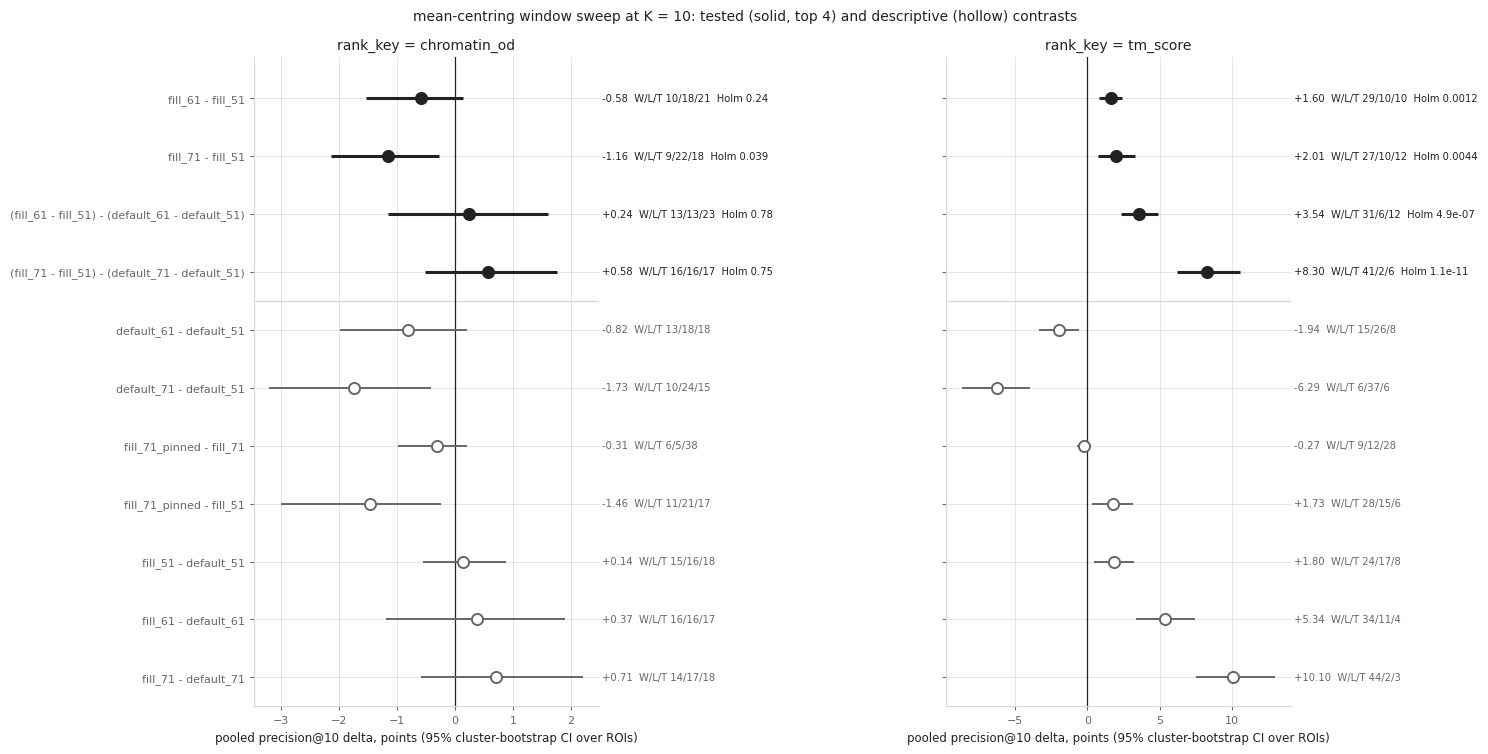

-> windowsweep_contrasts.png


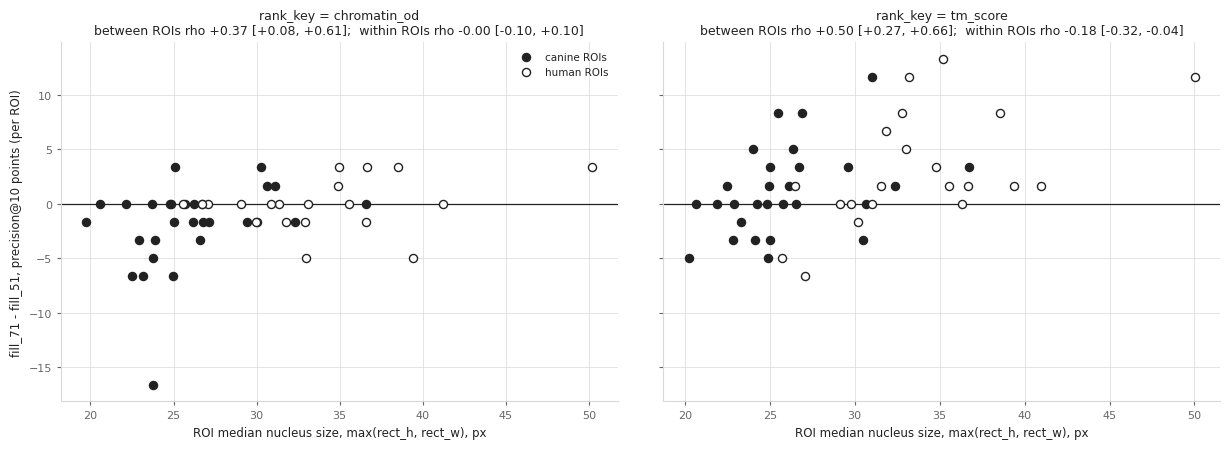

-> windowsweep_size.png

notebook total: 93.9 min


In [11]:
INK, MUTED, GRID = '#222222', '#666666', '#d8d8d8'


def recessive(ax):
    """
        Push an axes' frame and grid behind the data, the house style for every panel here.

        ax (matplotlib.axes.Axes): the axes to restyle.

        Returns None.
    """
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8, length=3)
    ax.grid(True, color=GRID, linewidth=0.6, alpha=0.8)
    ax.set_axisbelow(True)


# Figure 1 -- every K = 10 contrast on both axes. Tested rows are solid with their Holm p; descriptive rows are hollow.
order = list(TESTED) + [c for c in CONTRASTS if c not in TEST_FAMILY]
fig, axes = plt.subplots(1, len(AXES), figsize=(7.5 * len(AXES), 0.55 * len(order) + 1.6), sharey=True)
for col, axis in enumerate(AXES):
    ax = axes[col]
    for j, name in enumerate(order):
        st = DELTA_STATS[(DELTA_STATS['rank_key'] == axis) & (DELTA_STATS['metric'] == 'tp_at_10') & (DELTA_STATS['contrast'] == name)].iloc[0]
        tested = st['role'] == 'tested'
        ax.plot([100 * st['ci_low'], 100 * st['ci_high']], [j, j], color=INK if tested else MUTED, linewidth=2.2 if tested else 1.4, solid_capstyle='butt', zorder=3)
        ax.plot([100 * st['pooled_delta_precision']], [j], marker='o', ms=8, color=INK if tested else 'white', markeredgecolor=INK if tested else MUTED, markeredgewidth=1.4, zorder=4)
        note = f"{100 * st['pooled_delta_precision']:+.2f}  W/L/T {int(st['wins'])}/{int(st['losses'])}/{int(st['ties'])}" + (f"  Holm {st['holm_p']:.2g}" if tested else '')
        ax.annotate(note, xy=(1.01, j), xycoords=('axes fraction', 'data'), fontsize=7.2, color=INK if tested else MUTED, va='center', ha='left', annotation_clip=False)
    ax.axvline(0, color=INK, linewidth=0.9, zorder=2)
    ax.axhline(len(TESTED) - 0.5, color=GRID, linewidth=1.0, zorder=1)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=7.5, color=INK)
    ax.set_ylim(len(order) - 0.5, -0.7)
    ax.set_xlabel(f'pooled precision@{TEST_K} delta, points (95% cluster-bootstrap CI over ROIs)', fontsize=8.5, color=INK)
    ax.set_title(f'rank_key = {axis}', fontsize=10, color=INK)
    recessive(ax)
fig.suptitle(f'mean-centring window sweep at K = {TEST_K}: tested (solid, top {len(TESTED)}) and descriptive (hollow) contrasts', fontsize=10, color=INK)
fig.tight_layout(w_pad=12.0)
fig.savefig(FIG_PATHS['contrasts'], dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)
print(f"-> {FIG_PATHS['contrasts']}")

# Figure 2 -- Q3, per-ROI fill_71 - fill_51 against ROI median nucleus size; filled = canine, hollow = human, since size is largely species here
fig, axes = plt.subplots(1, len(AXES), figsize=(6.2 * len(AXES), 4.6), sharey=True)
for col, axis in enumerate(AXES):
    ax, roi = axes[col], Q3_ROI[axis]
    jitter = np.random.default_rng(col).uniform(-0.25, 0.25, len(roi))
    for sp, face, lab in ((1, INK, 'canine ROIs'), (0, 'white', 'human ROIs')):
        m = (roi['canine'] == sp).to_numpy()
        ax.scatter(roi['nucleus_px'].to_numpy()[m] + jitter[m], roi['delta_pts'].to_numpy()[m], s=34, facecolors=face, edgecolors=INK, linewidths=1.0, zorder=3, label=lab)
    ax.axhline(0, color=INK, linewidth=0.9, zorder=2)
    b = Q3[(Q3['rank_key'] == axis) & Q3['level'].str.startswith('between')].iloc[0]
    w = Q3[(Q3['rank_key'] == axis) & Q3['level'].str.startswith('within')].iloc[0]
    ax.set_title(f"rank_key = {axis}\nbetween ROIs rho {b['spearman']:+.2f} [{b['ci_low']:+.2f}, {b['ci_high']:+.2f}];  within ROIs rho {w['spearman']:+.2f} [{w['ci_low']:+.2f}, {w['ci_high']:+.2f}]", fontsize=9, color=INK)
    ax.set_xlabel('ROI median nucleus size, max(rect_h, rect_w), px', fontsize=8.5, color=INK)
    if col == 0:
        ax.set_ylabel(f'fill_71 - fill_51, precision@{TEST_K} points (per ROI)', fontsize=8.5, color=INK)
        ax.legend(fontsize=7.5, frameon=False, labelcolor=INK, loc='upper right')
    recessive(ax)
fig.tight_layout(w_pad=3.0)
fig.savefig(FIG_PATHS['size'], dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)
print(f"-> {FIG_PATHS['size']}")
print(f'\nnotebook total: {(time.time() - NB_T0) / 60:.1f} min')

**Reading the two figures.**
- Figure 1's two panels are scaled separately: the `chromatin_od` data span -3.20 to +2.21 points, the `tm_score` data
  -8.71 to +12.99. Equal bar lengths in the two panels are not equal effects.
- In Figure 2, 18 of 49 ROIs at `chromatin_od` and 12 of 49 at `tm_score` have a `fill_71 - fill_51` delta of exactly 0
  (the ties in the Q1 table). They sit on the zero line, and the +/-0.25 px jitter does not separate them all.

## Post-run inspection of the near-seed flag

**Added after the run.** The near-seed diagnostic fired, so this cell looks at what the flagged detections are. It reads
only the saved `per_run` and `top30` CSVs and depends on nothing held in memory, so it was executed on its own rather than
by re-running the 92-minute loop. Its execution count (12) follows the run's, but it was executed separately, 208 s after
the last run cell finished, not as part of the run-through. It changes no number above.

In [12]:
import numpy as np
import pandas as pd

STEM = '../results/precision_at_k_49roi_6seed_windowsweep_postD11'
ARMS = ('default_51', 'fill_51', 'default_61', 'fill_61', 'default_71', 'fill_71', 'fill_71_pinned')
AXES = ('chromatin_od', 'tm_score')
run = pd.read_csv(f'{STEM}_per_run.csv', float_precision='round_trip')
top = pd.read_csv(f'{STEM}_top30.csv', float_precision='round_trip')
assert (len(run), len(top)) == (4116, 123480), 'the saved outputs are not the full run'
t = top.merge(run[['file_name', 'seed_index', 'click_cx', 'click_cy']].drop_duplicates(), on=['file_name', 'seed_index'], validate='many_to_one')
t['cheb_px'] = np.maximum((t['cx'] - t['click_cx']).abs(), (t['cy'] - t['click_cy']).abs())
t['click'] = t['file_name'] + '#' + t['seed_index'].astype(str)
grid = pd.MultiIndex.from_product([ARMS, AXES], names=['condition', 'rank_key'])

near_fp = t[(t['rank'] < 10) & (t['cheb_px'] <= 60) & (t['bucket'] != 'human_correct_label')]
print('near-seed top-10 detections that are NOT true positives (Chebyshev <= 60 px of the click), by arm and axis:')
print(near_fp.groupby(['condition', 'rank_key']).agg(n_slots=('rank', 'size'), n_clicks=('click', 'nunique'), n_rois=('file_name', 'nunique'), cheb_px_min=('cheb_px', 'min'), cheb_px_max=('cheb_px', 'max'), rank_min=('rank', 'min'), rank_median=('rank', 'median'), rank_max=('rank', 'max'), buckets=('bucket', lambda b: ';'.join(sorted(set(b))))).reindex(grid).dropna(how='all').to_string())

on_click = t[t['cheb_px'] <= 2]
print('\na detection within 2 px of the click anywhere in the top 30 -- the seed matching itself -- by arm and axis (of 294 click lists each):')
print(on_click.groupby(['condition', 'rank_key']).agg(n_lists=('click', 'nunique'), in_top10=('rank', lambda r: int((r < 10).sum())), rank_median=('rank', 'median'), buckets=('bucket', lambda b: ';'.join(sorted(set(b))))).reindex(grid).fillna({'n_lists': 0, 'in_top10': 0}).to_string())

near-seed top-10 detections that are NOT true positives (Chebyshev <= 60 px of the click), by arm and axis:
                         n_slots  n_clicks  n_rois  cheb_px_min  cheb_px_max  rank_min  rank_median  rank_max             buckets
condition  rank_key                                                                                                              
default_61 tm_score          3.0       3.0     3.0          0.0          2.0       2.0          3.0       9.0  non_human_findings
default_71 chromatin_od      4.0       4.0     3.0          0.0          0.0       0.0          3.5       5.0  non_human_findings
           tm_score         17.0      17.0    10.0          0.0          1.0       0.0          1.0       7.0  non_human_findings

a detection within 2 px of the click anywhere in the top 30 -- the seed matching itself -- by arm and axis (of 294 click lists each):
                             n_lists  in_top10  rank_median             buckets
condition      rank_key    

## Post-run: how much the self-match moves the contrasts it enters

**Added after the audit (2026-09-29).** The self-match sits in `default_61` / `default_71`, so it enters
`default_W - default_51` and both difference-in-differences. This cell measures by how much, on both axes.

- **Self-match dropped.** Every detection within 2 px of the click is unmatched (`non_human_findings`, asserted), so
  dropping it from a list and re-taking the top 10 moves no other detection's bucket. The top 30 gives that new top 10
  exactly.
- **Worst case, `tm_score` only.** The top 30 cannot see one channel: NMS un-suppression. A self-match peak can have
  suppressed a true positive only if another mitosis lies within 2 r + 3 px of the click: r to the suppressed peak (NMS
  radius = match radius, D7), r on to its mitosis, and 3 px for the self-match's own offset. The worst case counts every
  self-match top-10 slot as a displaced true positive, plus one true positive for every such mitosis. At `tm_score` that
  bounds the self-match's effect, because the one other new peak, the 101st admitted by the freed pool slot, scores lowest
  and ranks last. At `chromatin_od` that peak can have any `od` and enter the top 10 anywhere, so no bound is claimed.

It also compares the fill arms' near-seed top-10 detections with `fill_51`'s by exact `(cx, cy)`, and prints the fill
templates' smallest mass weight `m_k - f_W`.

It reads only the saved `per_run`, `top30` and `delta_stats` CSVs and `MIDOG++.json`, and writes
`precision_at_k_49roi_6seed_windowsweep_postD11_selfmatch_sensitivity.csv`; its as-recorded rows must equal the saved
`delta_stats`. It was run in a separate kernel after the configuration, inputs and statistics-validation cells (execution
counts 1-3 above), not by re-running the loop, so its execution count is that kernel's. It changes no number above.

In [5]:
# post-run, from the saved CSVs only (see the markdown above): needs the configuration, inputs and statistics cells, not the loop
SELF_PX = 2   # a detection this close (Chebyshev) to the click is the seed matching itself (cell 21)
SM_CONTRASTS = ('default_61 - default_51', 'default_71 - default_51', '(fill_61 - fill_51) - (default_61 - default_51)', '(fill_71 - fill_51) - (default_71 - default_51)')
LIST_KEY = ['file_name', 'seed_index', 'condition', 'rank_key']
SM_OUT = f'{OUT_STEM}_selfmatch_sensitivity.csv'
assert SMOKE_ROIS is None and not SM_OUT.startswith(SRC), 'this check reads the full run and writes beside it'

run = pd.read_csv(OUT['per_run'], float_precision='round_trip')
top = pd.read_csv(OUT['top30'], float_precision='round_trip').sort_values(LIST_KEY + ['rank'], kind='stable')
saved_stats = pd.read_csv(OUT['delta_stats'], float_precision='round_trip')
assert (len(run), len(top)) == (4116, 123480), 'the saved outputs are not the full run'
t = top.merge(run[['file_name', 'seed_index', 'click_cx', 'click_cy']].drop_duplicates(), on=['file_name', 'seed_index'], validate='many_to_one')
t['cheb_px'] = np.maximum((t['cx'] - t['click_cx']).abs(), (t['cy'] - t['click_cy']).abs())
t['hit'] = t['bucket'] == ev.HUMAN_CORRECT_LABEL
run = run.set_index(LIST_KEY)
assert (t[t['rank'] < TEST_K].groupby(LIST_KEY)['hit'].sum().reindex(run.index) == run['tp_at_10']).all(), 'the saved top 30 does not reproduce the saved TP@10'

# 1. drop the self-match from each list, re-take the top 10. It claims no ground truth, so no other detection's bucket moves.
self_match = t[t['cheb_px'] <= SELF_PX]
assert (self_match['bucket'] == ev.NON_HUMAN_FINDINGS).all() and (self_match['matched_ann_id'] == -1).all(), 'a self-match claimed a ground truth, so dropping it would change later matches'
kept = t[t['cheb_px'] > SELF_PX].copy()
kept['rank_after_drop'] = kept.groupby(LIST_KEY).cumcount()
run['tp_at_10_selfmatch_dropped'] = kept[kept['rank_after_drop'] < TEST_K].groupby(LIST_KEY)['hit'].sum().reindex(run.index)
run['tp_hidden'] = run['tp_at_10_selfmatch_dropped'] - run['tp_at_10']
assert run['tp_hidden'].notna().all() and (run['tp_hidden'] >= 0).all(), 'dropping a false positive cannot lose a true positive'
hidden = pd.concat([self_match[self_match['rank'] < TEST_K].groupby(['condition', 'rank_key']).size().rename('selfmatch_top10_slots'), run.groupby(['condition', 'rank_key'])['tp_hidden'].sum().rename('tp_hidden_by_them')], axis=1).fillna(0).astype(int)
print(f'self-match top-{TEST_K} slots (a detection within {SELF_PX} px of the click) and the true positives they hid, by arm and axis (every other arm: 0 and 0):')
print(hidden[(hidden != 0).any(axis=1)].to_string())

# 2. the one channel the top 30 cannot see: NMS un-suppression. A self-match peak (at most 2 * sqrt(2) px from the click) can only have suppressed a
#    true positive if another mitosis lies within 2 r + 3 px of the click: r to the suppressed peak (NMS radius = match radius, D7), r on to its mitosis.
clicks = run.reset_index().drop_duplicates(['file_name', 'seed_index'])[['file_name', 'seed_index', 'seed_ann_id', 'match_radius_px', 'click_cx', 'click_cy']]
pairs = clicks.merge(annotations.loc[annotations['category_id'] == ds.MITOTIC, ['file_name', 'ann_id', 'cx', 'cy']], on='file_name')
pairs = pairs[pairs['ann_id'] != pairs['seed_ann_id']]
pairs['dist_px'] = np.hypot(pairs['cx'] - pairs['click_cx'], pairs['cy'] - pairs['click_cy'])
near_gt = clicks.set_index(['file_name', 'seed_index']).assign(within_r=pairs[pairs['dist_px'] <= pairs['match_radius_px']].groupby(['file_name', 'seed_index']).size(), within_2r=pairs[pairs['dist_px'] <= 2 * pairs['match_radius_px'] + 3].groupby(['file_name', 'seed_index']).size()).fillna({'within_r': 0, 'within_2r': 0})
print(f"\nclicks with another mitosis within r of the click: {int((near_gt['within_r'] > 0).sum())}; within 2 r + 3 px: {int((near_gt['within_2r'] > 0).sum())} (of {len(near_gt)}), at most {int(near_gt['within_2r'].max())} per click")


def roi_table(col, axis):
    """
        Per-ROI click-summed TP@10 of every arm on one ranking axis.

        col (str): the per-run TP column to sum.
        axis (str): the ranking axis.

        Returns pd.DataFrame: one row per ROI in the bootstrap's ROI order, one column per arm.
    """
    return run.xs(axis, level='rank_key').groupby(['file_name', 'condition'])[col].sum().unstack('condition').reindex(ROI_ORDER_ALL)[list(ARMS)]


# 3. the contrasts that contain a default_W arm: as recorded, with the self-match dropped, and (tm_score only) a worst case
BOOT_IDX49 = boot_index(len(ROI_ORDER_ALL))
sm_rows = []
for axis in AXES:
    versions = {'as recorded': roi_table('tp_at_10', axis), 'self-match dropped': roi_table('tp_at_10_selfmatch_dropped', axis)}
    if axis == 'tm_score':
        # ranking is by the NMS key here, so an un-suppressed peak enters below the self-match and the 101st peak ranks last:
        # every self-match slot counted as a displaced TP, plus one TP for every other mitosis within 2 r + 3 px of a click, bounds the self-match's effect
        worst = versions['as recorded'].copy()
        slots = self_match[(self_match['rank'] < TEST_K) & (self_match['rank_key'] == axis)].groupby(['condition', 'file_name']).size()
        near_2r_per_roi = near_gt['within_2r'].astype(int).groupby('file_name').sum().reindex(ROI_ORDER_ALL)
        for arm in ('default_61', 'default_71'):
            worst[arm] = worst[arm] + (slots.loc[arm].reindex(ROI_ORDER_ALL, fill_value=0) if arm in slots.index.get_level_values(0) else 0) + near_2r_per_roi
        versions['worst case'] = worst
    for version, tab in versions.items():
        for name in SM_CONTRASTS:
            d = sum(c * tab[arm] for arm, c in CONTRASTS[name].items()).to_numpy().astype(np.int64)
            sm_rows.append(dict(rank_key=axis, contrast=name, version=version, **pair_stats(d, TEST_K, BOOT_IDX49)))
SM_STATS = pd.DataFrame(sm_rows)
check = SM_STATS[SM_STATS['version'] == 'as recorded'].merge(saved_stats[saved_stats['metric'] == 'tp_at_10'], on=['rank_key', 'contrast'], suffixes=('', '_saved'))
assert len(check) == 2 * len(SM_CONTRASTS) and all((check[c] == check[f'{c}_saved']).all() for c in ('pooled_delta_precision', 'ci_low', 'ci_high', 'exact_p', 'wins', 'losses', 'ties', 'd5_bar_met')), 'the as-recorded rows do not reproduce the saved delta_stats'
SM_STATS.to_csv(SM_OUT, index=False)
print(f'\n-> {SM_OUT}  ({len(SM_STATS)} rows; the as-recorded rows equal the saved delta_stats)')
for axis in AXES:
    print(f'\n--- rank_key = {axis}, K = {TEST_K}' + (' (worst case = every self-match slot a displaced TP, plus one TP per other mitosis within 2 r + 3 px of a click)' if axis == 'tm_score' else ' (no worst case: ranking is by od, so a freed pool slot can enter the top 10 anywhere, and nothing here bounds it)') + ' ---')
    f = SM_STATS[SM_STATS['rank_key'] == axis]
    print(f.assign(delta_pts=(100 * f['pooled_delta_precision']).round(2), boot_ci95_pts=[f'[{100 * lo:+.2f}, {100 * hi:+.2f}]' for lo, hi in zip(f['ci_low'], f['ci_high'])], wlt=f['wins'].astype(str) + '/' + f['losses'].astype(str) + '/' + f['ties'].astype(str))[['contrast', 'version', 'delta_pts', 'boot_ci95_pts', 'wlt', 'exact_p', 'ci_excludes_0', 'd5_bar_met']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

# 4. are the fill arms' near-seed top-10 detections the very same pixels as fill_51's?
near10 = t[(t['rank'] < TEST_K) & (t['cheb_px'] <= NEAR_SEED_PX)]
near_sets = {k: frozenset(zip(g['cx'], g['cy'])) for k, g in near10.groupby(LIST_KEY)}
print(f'\nnear-seed (Chebyshev <= {NEAR_SEED_PX} px) top-{TEST_K} detections, compared by exact (cx, cy) with fill_51 on the same click:')
for axis in AXES:
    for arm in ('fill_61', 'fill_71', 'fill_71_pinned'):
        differ = [(fn, s) for fn in ROI_ORDER_ALL for s in SEED_INDICES if near_sets.get((fn, s, arm, axis), frozenset()) != near_sets.get((fn, s, 'fill_51', axis), frozenset())]
        detail = '; '.join(f"{fn} s{s}: {arm} {sorted(near_sets.get((fn, s, arm, axis), frozenset()))} vs fill_51 {sorted(near_sets.get((fn, s, 'fill_51', axis), frozenset()))}" for fn, s in differ)
        print(f'  {axis:13s} {arm:15s} identical on {len(near_gt) - len(differ)}/{len(near_gt)} clicks' + (f'  ({detail})' if differ else ''))

# 5. the fill templates' mass weight m_k - f_W, which signs their response at the click
mw = run[run.index.get_level_values('condition').isin(FILL_ARMS)].groupby(level='condition')['mass_weight'].min()
assert (mw > 0).all(), 'a fill template has a non-positive mass weight'
print(f'\nsmallest mass weight m_k - f_W per fill arm (all > 0): {mw.round(4).to_dict()}')


self-match top-10 slots (a detection within 2 px of the click) and the true positives they hid, by arm and axis (every other arm: 0 and 0):
                         selfmatch_top10_slots  tp_hidden_by_them
condition  rank_key                                              
default_61 tm_score                          3                  0
default_71 chromatin_od                      4                  3
           tm_score                         17                  5

clicks with another mitosis within r of the click: 0; within 2 r + 3 px: 12 (of 294), at most 1 per click

-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_selfmatch_sensitivity.csv  (20 rows; the as-recorded rows equal the saved delta_stats)

--- rank_key = chromatin_od, K = 10 (no worst case: ranking is by od, so a freed pool slot can enter the top 10 anywhere, and nothing here bounds it) ---
                                       contrast            version  delta_pts  boot_ci95_pts      wlt  exact_p  ci_excl


smallest mass weight m_k - f_W per fill arm (all > 0): {'fill_51': 0.0122, 'fill_61': 0.0124, 'fill_71': 0.0111, 'fill_71_pinned': 0.0122}


## Follow-up (2026-09-30): `default_61` / `default_71` with a blank covering their own footprint

**Added after the run, by decision (user, 2026-09-30).** With the blank fixed at 51 px, the outer ring of an untouched
61 / 71 px template stays unblanked, and at the click it matches itself (post-run inspection above). D11 as written
blanks the template's own footprint. These two cells re-search only `default_61` and `default_71`, with a 61 x 61 and a
71 x 71 blank, which leaves the self-match no source pixels. Everything else is unchanged: the same templates (SHA-1
asserted against the recorded run), clicks, search, NMS, `od` and matching. The recorded run above is left as run, and the
follow-up's numbers sit beside it.

- **The gate.** With the recorded 51 px blank, the same code must first reproduce the recorded `default_61` /
  `default_71` rows exactly on `337.tiff` and `509.tiff`, so the blank is the only change.
- **Not re-searched, by decision:** `default_51`, whose blank already equals its footprint, and every fill arm. The fill
  arms stay on the 51 px blank, so within each W the two arms of a contrast now have different blanks. That is fair only
  if the fill arms are insensitive to the blank size. The audit measured `fill_61` / `fill_71` with a 61 / 71 px blank and
  found TP@10 changed on 1 of 1176 lists (`Research Logs/2026-09-29-window-sweep-51-61-71-49roi-6seed-audit.md`,
  finding 4).
- **A bigger blank has its own cost:** it can also hide a real mitosis near the click. The second cell counts what
  changed, list by list.

They read only the saved CSVs and the ROI images, and write
`precision_at_k_49roi_6seed_windowsweep_postD11_blankW_{per_run,top30,delta_stats}.csv`. They were run in a separate
kernel after the configuration, inputs, statistics and template/search cells (execution counts 1-4 above), not by
re-running the loop, so their execution counts are that kernel's. They change no number above.


In [6]:
# follow-up, 2026-09-30: default_61 / default_71 re-searched with a blank covering their own footprint (see the markdown above);
# needs the configuration, inputs, statistics and template/search cells, not the loop
REBLANK_ARMS = ('default_61', 'default_71')
REBLANK_OUT = {name: f'{OUT_STEM}_blankW_{name}.csv' for name in ('per_run', 'top30')}
GATE_ROIS = ('337.tiff', '509.tiff')
SELF_PX = 2
assert SMOKE_ROIS is None and not set(REBLANK_OUT.values()) & set(OUT.values()) and not any(p.startswith(SRC) for p in REBLANK_OUT.values()), 'the follow-up reads the full run and writes new files only'
SAVED_RUN = pd.read_csv(OUT['per_run'], float_precision='round_trip').set_index(['file_name', 'seed_index', 'condition', 'rank_key']).sort_index()
SAVED_TOP = pd.read_csv(OUT['top30'], float_precision='round_trip')
SAVED_TOP_IX = {k: g.sort_values('rank') for k, g in SAVED_TOP[SAVED_TOP['condition'].isin(REBLANK_ARMS)].groupby(['file_name', 'seed_index', 'condition', 'rank_key'])}
assert len(SAVED_RUN) == 4116 and len(SAVED_TOP_IX) == 2 * 294 * 2, 'the saved outputs are not the full run'


def reblank_roi(file_name, footprint_blank):
    """
        Re-search default_61 and default_71 on every click of one ROI, with either a footprint-sized or the recorded 51 px blank.

        file_name (str): the ROI.
        footprint_blank (bool): True blanks W x W, the template's own footprint (D11's wording); False blanks 51 x 51, as the recorded run did.

        Returns tuple[list[dict], list[pd.DataFrame], list[tuple]]: per_run rows, top-30 frames, and (tag, row, ranked output) for the parity check.
    """
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f"{file_name}: mpp {mpp!r} != the recorded {rows['mpp'].iat[0]!r}"
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    od_padded = {W: padded(hem, PADS[W]) for W in (61, 71)}
    gt = ds.image_annotations(annotations, file_name)
    nms_radius = match_radius = ev.radius_px(mpp)
    out_rows, out_tops, checks = [], [], []
    for r in rows.itertuples():
        cx, cy, s = float(r.click_cx), float(r.click_cy), int(r.seed_index)
        arms, _, _ = build_templates(hem, cx, cy, (int(r.rect_y0), int(r.rect_y1), int(r.rect_x0), int(r.rect_x1)))
        gt_eval = gt[gt['ann_id'] != r.seed_ann_id].reset_index(drop=True)
        for arm in REBLANK_ARMS:
            W, T = ARM_W[arm], arms[arm]['T']
            sha = template_sha1(T)
            assert all(sha == SAVED_RUN.loc[(file_name, s, arm, axis), 'tpl_sha1'] for axis in AXES), f'{file_name} s{s} {arm}: the template differs from the recorded run'
            blank = W if footprint_blank else BLANK_SIZE
            search, n_blanked = tm.blank_seed_square(hem, cx, cy, blank)
            assert n_blanked == blank ** 2, f'{file_name} s{s} {arm}: {n_blanked} px blanked, not {blank ** 2}'
            t0 = time.time()
            det, info = search_once(padded(search, PADS[W]), od_padded[W], hem.shape, T, PADS[W], nms_radius)
            t_search = time.time() - t0
            del search
            assert info['n_detections'] >= TEST_K, f"{file_name} s{s} {arm}: {info['n_detections']} detections"
            for axis in AXES:
                ranked = rank_by(det, axis)
                out, tp = score_top_k(ranked, gt_eval, match_radius)
                tp_xb, n_kept_xb, n_band_top10 = tp_excl_border(ranked, gt_eval, match_radius, hem.shape)
                top30 = out.head(30)
                cheb30 = np.maximum((top30['cx'] - cx).abs(), (top30['cy'] - cy).abs()).to_numpy()
                not_tp10 = (top30['bucket'].to_numpy()[:TEST_K] != ev.HUMAN_CORRECT_LABEL)
                row = dict(subset=r.subset, domain=r.domain, file_name=file_name, seed_index=s, condition=arm, W=W, blank_px=blank, rank_key=axis, seed_ann_id=int(r.seed_ann_id), click_cx=cx, click_cy=cy, mpp=mpp, match_radius_px=match_radius, tpl_sha1=sha,
                           n_kept_px=W * W, n_filled_px=0, fill_value=np.nan, n_peaks=info['n_peaks'], n_detections=info['n_detections'], n_nms_suppressed=info['n_peaks'] - info['n_detections'], n_blanked_px=n_blanked, t_search_s=round(t_search, 3),
                           **{f'tp_at_{k}': tp[k] for k in BUDGETS}, tp_at_10_excl_border=tp_xb, n_detections_excl_border=n_kept_xb, n_border_band_top10=n_band_top10, **near_seed_counts(out, cx, cy),
                           n_near_seed_fp_top10_reach=int(((cheb30[:TEST_K] <= blank // 2 + PADS[W]) & not_tp10).sum()), n_selfmatch_top10=int((cheb30[:TEST_K] <= SELF_PX).sum()), n_selfmatch_top30=int((cheb30 <= SELF_PX).sum()))
                out_rows.append(row)
                out_tops.append(top30[['rank', 'cx', 'cy', 'score', 'od', 'bucket', 'matched_ann_id', 'matched_category']].assign(file_name=file_name, seed_index=s, condition=arm, rank_key=axis))
                checks.append((f'{file_name} s{s} {arm} @ {axis}', row, out))
    del hem, od_padded
    gc.collect()
    return out_rows, out_tops, checks


# the gate: with the recorded 51 px blank, this code must reproduce the recorded default_61 / default_71 rows exactly, so the blank is the only change
n_gate, n_gate_od_exact = 0, 0
for file_name in GATE_ROIS:
    _, _, checks = reblank_roi(file_name, footprint_blank=False)
    for tag, row, out in checks:
        key = (row['file_name'], row['seed_index'], row['condition'], row['rank_key'])
        n_gate_od_exact += parity_gate(tag, row, out, SAVED_RUN.loc[key], SAVED_TOP_IX[key])
        n_gate += 1
print(f'gate: with the recorded 51 px blank, default_61 / default_71 reproduce the recorded rows on {n_gate}/{n_gate} (click, arm, axis) rows of {", ".join(GATE_ROIS)}; top-30 od bit-exact on {n_gate_od_exact}/{30 * n_gate}')

# the follow-up: the same two arms, the blank now covering the template's own footprint
rb_rows, rb_tops = [], []
t_rb = time.time()
for i, file_name in enumerate(ROI_ORDER_ALL):
    new_rows, new_tops, _ = reblank_roi(file_name, footprint_blank=True)
    rb_rows += new_rows
    rb_tops += new_tops
    pd.DataFrame(rb_rows).to_csv(REBLANK_OUT['per_run'], index=False)
    pd.concat(rb_tops, ignore_index=True).to_csv(REBLANK_OUT['top30'], index=False)
    print(f'[{i + 1}/{len(ROI_ORDER_ALL)} {file_name}] {(time.time() - t_rb) / 60:.1f} min', flush=True)
REBLANK = pd.DataFrame(rb_rows)
assert len(REBLANK) == 294 * len(REBLANK_ARMS) * len(AXES), 'the follow-up is not one row per (click, arm, axis)'
print(f"\n-> {REBLANK_OUT['per_run']}, {REBLANK_OUT['top30']}  ({len(REBLANK)} rows; {len(REBLANK) // len(AXES)} searches in {(time.time() - t_rb) / 60:.1f} min)")


gate: with the recorded 51 px blank, default_61 / default_71 reproduce the recorded rows on 48/48 (click, arm, axis) rows of 337.tiff, 509.tiff; top-30 od bit-exact on 1440/1440


[1/49 300.tiff] 0.6 min


[2/49 301.tiff] 1.3 min


[3/49 322.tiff] 1.9 min


[4/49 337.tiff] 2.4 min


...

[46/49 364.tiff] 33.7 min


[47/49 400.tiff] 34.6 min


[48/49 401.tiff] 35.6 min


[49/49 404.tiff] 36.7 min



-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_blankW_per_run.csv, ../results/precision_at_k_49roi_6seed_windowsweep_postD11_blankW_top30.csv  (1176 rows; 588 searches in 36.7 min)


In [7]:
# follow-up, continued: what the footprint blank changes, and the contrasts that contain default_61 / default_71
FOLLOWUP_CONTRASTS = ('default_61 - default_51', 'default_71 - default_51', '(fill_61 - fill_51) - (default_61 - default_51)', '(fill_71 - fill_51) - (default_71 - default_51)', 'fill_61 - default_61', 'fill_71 - default_71')
REBLANK_STATS_OUT = f'{OUT_STEM}_blankW_delta_stats.csv'
KEY = ['file_name', 'seed_index', 'condition', 'rank_key']
old = SAVED_RUN.reset_index()
both = REBLANK.merge(old[KEY + ['tp_at_10', 'n_near_seed_fp_top10_cheb', 'n_near_seed_fp_top10_euclid']], on=KEY, suffixes=('', '_blank51'), validate='one_to_one')
assert len(both) == len(REBLANK)

# self-match with the recorded 51 px blank, from the saved top 30 (cell 21's definition)
saved_sm = SAVED_TOP[SAVED_TOP['condition'].isin(REBLANK_ARMS)].merge(old[KEY + ['click_cx', 'click_cy']], on=KEY)
saved_sm = saved_sm[np.maximum((saved_sm['cx'] - saved_sm['click_cx']).abs(), (saved_sm['cy'] - saved_sm['click_cy']).abs()) <= SELF_PX]
sm51 = saved_sm.groupby(['condition', 'rank_key']).agg(selfmatch_top10_blank51=('rank', lambda r: int((r < TEST_K).sum())), selfmatch_top30_blank51=('rank', 'size'))
change = both.groupby(['condition', 'rank_key']).agg(lists=('tp_at_10', 'size'), lists_tp10_changed=('tp_at_10', lambda v: int((v != both.loc[v.index, 'tp_at_10_blank51']).sum())), net_tp10_change=('tp_at_10', lambda v: int(v.sum() - both.loc[v.index, 'tp_at_10_blank51'].sum())),
                                                      selfmatch_top10=('n_selfmatch_top10', 'sum'), selfmatch_top30=('n_selfmatch_top30', 'sum'), near_seed_fp_60px_blank51=('n_near_seed_fp_top10_cheb_blank51', 'sum'), near_seed_fp_60px=('n_near_seed_fp_top10_cheb', 'sum'), near_seed_fp_60px_euclid=('n_near_seed_fp_top10_euclid', 'sum'), near_seed_fp_full_reach=('n_near_seed_fp_top10_reach', 'sum'))
change = change.join(sm51).fillna(0).astype(int)
print('what the footprint blank changes, per arm and axis (blank51 = the recorded run; full reach = W - 1 px, where a W template overlaps a W blank):')
print(change[['lists', 'lists_tp10_changed', 'net_tp10_change', 'selfmatch_top10_blank51', 'selfmatch_top10', 'selfmatch_top30_blank51', 'selfmatch_top30', 'near_seed_fp_60px_blank51', 'near_seed_fp_60px', 'near_seed_fp_60px_euclid', 'near_seed_fp_full_reach']].to_string())
wide_fp_after = int(change[['near_seed_fp_60px', 'near_seed_fp_60px_euclid']].to_numpy().sum()) + int(old[old['condition'].isin(FILL_ARMS) & (old['W'] > BASE_SIZE)][['n_near_seed_fp_top10_cheb', 'n_near_seed_fp_top10_euclid']].to_numpy().sum())
print(f"\nthe pre-registered near-seed count over every wide arm (footprint-blanked default_61 / default_71 + the recorded fill_61 / fill_71 / fill_71_pinned), both definitions, both axes: {wide_fp_after}")


def roi_tp10(frame, axis):
    """
        Per-ROI click-summed TP@10 of every arm on one axis.

        frame (pd.DataFrame): per_run rows with file_name, condition, rank_key and tp_at_10.
        axis (str): the ranking axis.

        Returns pd.DataFrame: one row per ROI in the bootstrap's ROI order, one column per arm.
    """
    return frame[frame['rank_key'] == axis].groupby(['file_name', 'condition'])['tp_at_10'].sum().unstack('condition').reindex(ROI_ORDER_ALL)


BOOT_IDX49 = boot_index(len(ROI_ORDER_ALL))
fu_rows = []
for axis in AXES:
    recorded = roi_tp10(old, axis)
    footprint = recorded.copy()
    footprint[list(REBLANK_ARMS)] = roi_tp10(REBLANK, axis)[list(REBLANK_ARMS)]
    for version, tab in (('recorded (51 px blank)', recorded), ('default_61 / default_71 with a footprint blank', footprint)):
        for name in FOLLOWUP_CONTRASTS:
            d = sum(c * tab[arm] for arm, c in CONTRASTS[name].items()).to_numpy().astype(np.int64)
            fu_rows.append(dict(rank_key=axis, contrast=name, version=version, **pair_stats(d, TEST_K, BOOT_IDX49)))
FOLLOWUP = pd.DataFrame(fu_rows)
saved_stats = pd.read_csv(OUT['delta_stats'], float_precision='round_trip')
chk = FOLLOWUP[FOLLOWUP['version'].str.startswith('recorded')].merge(saved_stats[saved_stats['metric'] == 'tp_at_10'], on=['rank_key', 'contrast'], suffixes=('', '_saved'))
assert len(chk) == 2 * len(FOLLOWUP_CONTRASTS) and all((chk[c] == chk[f'{c}_saved']).all() for c in ('pooled_delta_precision', 'ci_low', 'ci_high', 'exact_p', 'wins', 'losses', 'ties', 'd5_bar_met')), 'the recorded rows do not reproduce the saved delta_stats'
# Holm over the two difference-in-differences per axis, the pre-registered family, now on the follow-up's numbers
FOLLOWUP['holm_p'] = np.nan
for (axis, version), g in FOLLOWUP[FOLLOWUP['contrast'].str.startswith('(')].groupby(['rank_key', 'version']):
    FOLLOWUP.loc[g.index, 'holm_p'] = holm_adjust(g['exact_p'].to_numpy())
FOLLOWUP.to_csv(REBLANK_STATS_OUT, index=False)
print(f'\n-> {REBLANK_STATS_OUT}  ({len(FOLLOWUP)} rows; the recorded rows equal the saved delta_stats)')
for axis in AXES:
    f = FOLLOWUP[FOLLOWUP['rank_key'] == axis].assign(order=lambda x: x['contrast'].map(FOLLOWUP_CONTRASTS.index), footprint_second=lambda x: ~x['version'].str.startswith('recorded')).sort_values(['order', 'footprint_second'], kind='stable')
    print(f'\n--- rank_key = {axis}, K = {TEST_K} (Holm over the two difference-in-differences only) ---')
    print(f.assign(delta_pts=(100 * f['pooled_delta_precision']).round(2), boot_ci95_pts=[f'[{100 * lo:+.2f}, {100 * hi:+.2f}]' for lo, hi in zip(f['ci_low'], f['ci_high'])], t_ci95_pts=[f'[{100 * lo:+.2f}, {100 * hi:+.2f}]' for lo, hi in zip(f['t_ci_low'], f['t_ci_high'])], wlt=f['wins'].astype(str) + '/' + f['losses'].astype(str) + '/' + f['ties'].astype(str))[['contrast', 'version', 'delta_pts', 'boot_ci95_pts', 't_ci95_pts', 'wlt', 'n_nonzero', 'exact_p', 'holm_p', 'd5_bar_met']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))
for axis in AXES:
    pooled = {arm: REBLANK[(REBLANK['condition'] == arm) & (REBLANK['rank_key'] == axis)]['tp_at_10'].sum() / (TEST_K * 294) for arm in REBLANK_ARMS}
    print(f'\npooled precision@{TEST_K} at {axis} with the footprint blank: ' + ', '.join(f'{arm} {v:.4f}' for arm, v in pooled.items()))


what the footprint blank changes, per arm and axis (blank51 = the recorded run; full reach = W - 1 px, where a W template overlaps a W blank):


                         lists  lists_tp10_changed  net_tp10_change  selfmatch_top10_blank51  selfmatch_top10  selfmatch_top30_blank51  selfmatch_top30  near_seed_fp_60px_blank51  near_seed_fp_60px  near_seed_fp_60px_euclid  near_seed_fp_full_reach
condition  rank_key                                                                                                                                                                                                                                     
default_61 chromatin_od    294                   0                0                        0                0                        0                0                          0                  0                         0                        0
           tm_score        294                   0                0                        3                0                        3                0                          3                  0                         0                        0
def


-> ../results/precision_at_k_49roi_6seed_windowsweep_postD11_blankW_delta_stats.csv  (24 rows; the recorded rows equal the saved delta_stats)

--- rank_key = chromatin_od, K = 10 (Holm over the two difference-in-differences only) ---
                                       contrast                                        version  delta_pts  boot_ci95_pts     t_ci95_pts      wlt  n_nonzero  exact_p  holm_p  d5_bar_met
                        default_61 - default_51                         recorded (51 px blank)      -0.82 [-1.97, +0.20] [-1.94, +0.31] 13/18/18         31   0.1754     NaN       False
                        default_61 - default_51 default_61 / default_71 with a footprint blank      -0.82 [-1.97, +0.20] [-1.94, +0.31] 13/18/18         31   0.1754     NaN       False
                        default_71 - default_51                         recorded (51 px blank)      -1.73 [-3.20, -0.41] [-3.20, -0.27] 10/24/15         34   0.0233     NaN       False
                        d

## Reading the result

**The gate held.** `default_51` and `fill_51` reproduce the recorded fill-geometry run on all 1176 (click, arm, axis) rows,
with top-30 `od` bit-exact on 35280 / 35280. Asserts 1-4 held on all 2058 searches. Before any search ran, the statistics
code reproduced all 10 recorded fill-geometry `delta_stats` rows column for column.

### The near-seed flag fired -- lifted for Q1 by decision, kept for Q2

Under the pre-registered rule, the flag made every `fill_61` / `fill_71` gain on both axes unresolved. After the run,
the user lifted it for Q1 and kept it for Q2 (2026-09-29). The evidence below is why Q1's arms are clean. Q2 stays
unresolved because the rule requires it, not because the contamination is large: its measured size is given under Q2. A
follow-up that re-searches `default_61` / `default_71` with a blank covering their own footprint removes the self-match
entirely (follow-up above).

The rise sits **only in the untouched wide arms**. Top-10 non-TP detections within 60 px of the click, on both the
Chebyshev and the Euclidean definition:
- `default_61`: 3 at `tm_score`.
- `default_71`: 17 at `tm_score` and 4 at `chromatin_od`.
- `fill_61`, `fill_71` and `fill_71_pinned`: **0 on both axes**, the same as `fill_51` and the recorded run.

The post-run inspection shows what they are. **Every one lies 0-2 px from the click: it is the seed matching itself.**
`default_71` carries such a self-match in its top 30 on 24 of 294 lists at `tm_score` (17 of them inside the top 10) and
13 at `chromatin_od` (4 in the top 10).

This is **not** the `mu_W` tissue inflation the design anticipated. With the blank fixed at 51 px, the outer 5 / 10 px
ring of an untouched 61 / 71 px template is unblanked image, and at the click it matches itself pixel for pixel. The
click's own annotation is removed from the ground truth, so the self-match is scored a false positive. A fill template's
ring is a constant, and at the click itself its keep pixels land entirely on the blanked square. Measured: no fill arm has a
detection within 2 px of the click anywhere in its top 30.

D11 as written blanks the template's own footprint (a `W x W` square); this run fixed the blank at 51 px for every arm by
design. For the fill arms that still meets D11's reason for the blank: their only non-constant pixels, the keep region, lie
inside the 51 px square. For the untouched 61 / 71 px arms it does not, and their unblanked ring is what self-matches.

So the artefact lives in `default_61` / `default_71`, and it is small. At `tm_score` it takes 3 top-10 slots in
`default_61` and 17 in `default_71`, but those slots hid 0 and 5 true positives (post-run check above). It leaves
`default_61` unchanged and lowers `default_71` by 5 true positives of 2940 top-10 slots, so it raises the 71 px
difference-in-differences by 0.17 points and leaves the 61 px one unchanged. At `chromatin_od` its 4 slots in `default_71`
hid 3 true positives. It appears in **neither** arm of the two Q1 window contrasts. It is reported here, not netted out.
**Decision (user, 2026-09-29): the flag is lifted for the Q1 window contrasts, whose arms carry no near-seed rise, and
kept for Q2, whose `default_W` arms carry the self-match.** The flag on Q2 is kept under the rule; the self-match's
measured effect on Q2 is given below.

### Q1 -- does a wider window raise fill precision@10? (tested, K = 10)

| axis | contrast | delta, pts | boot CI | t CI | W/L/T | nonzero | exact p | Holm | D5 |
|---|---|---|---|---|---|---|---|---|---|
| `tm_score` | `fill_61 - fill_51` | **+1.60** | [+0.82, +2.41] | [+0.75, +2.44] | 29/10/10 | 39 | 0.0005846 | 0.001169 | **met†** (29/49) |
| `tm_score` | `fill_71 - fill_51` | **+2.01** | [+0.75, +3.30] | [+0.67, +3.34] | 27/10/12 | 37 | 0.004393 | 0.004393 | **met†** (27/49) |
| `chromatin_od` | `fill_61 - fill_51` | -0.58 | [-1.53, +0.14] | [-1.47, +0.31] | 10/18/21 | 28 | 0.2427 | 0.2427 | not met |
| `chromatin_od` | `fill_71 - fill_51` | **-1.16** | [-2.14, -0.27] | [-2.14, -0.17] | 9/22/18 | 31 | 0.01927 | 0.03854 | not met (22/49) |

† Only after the post-run lift of the near-seed flag. Under the pre-registered rule, which fired on this axis, these two
results are unresolved.

**At `tm_score`, widening the mean-centring window raises the fill template's precision@10: +1.60 points at 61 and +2.01
at 71** (an after-the-fact exception: the pre-registered near-seed rule fired on this axis, and the flag was lifted
after the run; see below). Both clear Holm and both meet D5: 29 and 27 of 49 ROIs improve, and 10 lose. Both
CIs exclude 0 on all 20 re-seeded bootstraps (closest bounds +0.78 and +0.71). Pooled precision@10 goes from 0.5265
(`fill_51`) to 0.5425 (`fill_61`) to 0.5466 (`fill_71`), so most of the gain has arrived by 61. Whether 71 beats 61 was
not tested.

**At `chromatin_od`, it does not help, and at 71 a loss is suggested but not established.** At 61 no difference is
detected (CI [-1.53, +0.14]). At 71, precision is 1.16 points lower: the CI excludes 0 and Holm is 0.0385, but only 22 of
49 ROIs lose, so D5 is not met, and with the edge band dropped the exact p is 0.07211 (Other diagnostics). The near-seed
rule covers gains, and this is a loss. **At 71 the two axes point in opposite directions; at 61 `chromatin_od` shows no
detectable change.** They are two outcomes, and neither replicates or cancels the other.

**Why the flag was lifted for Q1.** Four printed facts bear on it:
- Every fill arm has 0 near-seed non-TP detections, on both axes and both definitions.
- Every fill arm's *total* near-seed top-10 count equals `fill_51`'s: Chebyshev 3 / Euclidean 2 at `tm_score`, and
  Chebyshev 4 / Euclidean 2 at `chromatin_od`, all true positives. Compared by exact `(cx, cy)` (post-run check above),
  they are the same detections as `fill_51`'s on 294 / 294 clicks at `tm_score`, for every wide fill arm. At
  `chromatin_od` they are the same on 294 / 294 clicks for `fill_71` and `fill_71_pinned`, and on 293 / 294 for
  `fill_61`, which on `353.tiff` click 2 detects the same mitosis 1 px lower.
- No fill arm has a detection within 2 px of the click anywhere in its top 30.
- A fill template cannot match itself at the click. There its keep pixels all land on the constant blank, so its response
  reduces to `R = k (m_k - f_W)(min - mu_W)`. The mass weight `m_k - f_W` is positive on every fill row (smallest 0.0111,
  post-run check above), and `mu_W` cannot fall below the blank's `min`, so `R` at the click is never positive.

The flag fired only on `default_61` / `default_71`, which enter Q2, not Q1. The lift is still a post-run decision: under
the rule as pre-registered, Q1 at `tm_score` is unresolved.

### Q2 -- is the change specific to the fill template? (tested, difference-in-differences)

| axis | contrast | delta, pts | boot CI | t CI | W/L/T | nonzero | exact p | Holm | D5 |
|---|---|---|---|---|---|---|---|---|---|
| `tm_score` | `(fill_61 - fill_51) - (default_61 - default_51)` | +3.54 | [+2.31, +4.86] | [+2.21, +4.86] | 31/6/12 | 37 | 4.931e-07 | 4.931e-07 | met‡ (31/49) |
| `tm_score` | `(fill_71 - fill_51) - (default_71 - default_51)` | +8.30 | [+6.22, +10.54] | [+6.09, +10.51] | 41/2/6 | 43 | 5.457e-12 | 1.091e-11 | met‡ (41/49) |
| `chromatin_od` | `(fill_61 - fill_51) - (default_61 - default_51)` | +0.24 | [-1.16, +1.60] | [-1.20, +1.68] | 13/13/23 | 26 | 0.784 | 0.784 | not met |
| `chromatin_od` | `(fill_71 - fill_51) - (default_71 - default_51)` | +0.58 | [-0.51, +1.77] | [-0.63, +1.79] | 16/16/17 | 32 | 0.3737 | 0.7474 | not met |

‡ Unresolved under the pre-registered rule: the near-seed flag is kept for Q2 (see below). The follow-up with a footprint
blank (above) gives +3.54 and +8.13 at `tm_score`.

**Most of the `tm_score` difference-in-differences is the untouched window getting worse, not the fill getting better:**
- `default_61 - default_51` = -1.94 [-3.37, -0.58].
- `default_71 - default_51` = -6.29 [-8.71, -3.98], W/L/T 6/37/6.
- Against these, the fill arm gains +1.60 / +2.01.

**Q2 at `tm_score` stays unresolved under the pre-registered rule (flag kept, 2026-09-29).** The rule, not the size of the
contamination, is what keeps it open. The self-match sits in exactly those `default_W` arms, in 3 and 17 of their 2940
top-10 slots, but it moves the contrasts very little (post-run check above):

| `tm_score`, K = 10 | as recorded | self-match dropped | worst case |
|---|---|---|---|
| `(fill_61 - fill_51) - (default_61 - default_51)` | +3.54 [+2.31, +4.86], 31/6/12 | +3.54 [+2.31, +4.86], 31/6/12 | +3.03 [+1.84, +4.35], 30/9/10 |
| `(fill_71 - fill_51) - (default_71 - default_51)` | +8.30 [+6.22, +10.54], 41/2/6 | +8.13 [+6.09, +10.31], 41/2/6 | +7.31 [+5.37, +9.39], 40/5/4 |
| `default_61 - default_51` | -1.94 [-3.37, -0.58], 15/26/8 | -1.94 [-3.37, -0.58], 15/26/8 | -1.43 [-2.86, -0.10], 17/25/7 |
| `default_71 - default_51` | -6.29 [-8.71, -3.98], 6/37/6 | -6.12 [-8.47, -3.88], 6/37/6 | -5.31 [-7.55, -3.16], 8/33/8 |

Dropping the self-match is exact for everything the top 30 can see. The worst case also covers the one channel it cannot,
NMS un-suppression: it counts every self-match slot as a displaced true positive, plus one true positive for every other
mitosis within 2 r + 3 px of a click (12 clicks, one each), the only ones a self-match peak could have suppressed. At
`tm_score` it is a true bound, because the one other new peak, admitted by the freed pool slot, scores lowest and ranks
last. It is a bound, not an estimate: in it, `default_61 - default_51` has exact p 0.0535. Even in the worst case both
difference-in-differences keep a CI that excludes 0 and meet D5.

**At `chromatin_od`, no difference is detected** at either width. The CIs are the bound: [-1.16, +1.60] and [-0.51, +1.77].
No equivalence is claimed. With the self-match dropped they are +0.24 and +0.48 [-0.61, +1.63]. No worst case is claimed
on this axis: ranking is by `od`, so the peak a freed pool slot admits could enter the top 10 anywhere.

**Follow-up with a footprint blank (2026-09-30, the two cells above).** Re-searching `default_61` / `default_71` with a
61 x 61 and a 71 x 71 blank removes the self-match entirely: none in any top 30. No wide arm has a near-seed non-TP
detection, on either definition, on either axis, or out to each template's full reach (60 / 70 px). The larger blank
changes TP@10 on 5 `default_71` lists at `tm_score` (+5 true positives) and 3 at `chromatin_od` (+3), and on none of
`default_61`'s; no list lost a true positive to it. The corrected numbers equal the self-match-dropped ones above:

| K = 10, footprint blank | `tm_score` | `chromatin_od` |
|---|---|---|
| `(fill_61 - fill_51) - (default_61 - default_51)` | +3.54 [+2.31, +4.86], 31/6/12, Holm 4.931e-07, D5 met | +0.24 [-1.16, +1.60], 13/13/23, not met |
| `(fill_71 - fill_51) - (default_71 - default_51)` | +8.13 [+6.09, +10.31], 41/2/6, Holm 1.091e-11, D5 met | +0.48 [-0.61, +1.63], 16/16/17, not met |
| `default_61 - default_51` | -1.94 [-3.37, -0.58], 15/26/8 | -0.82 [-1.97, +0.20], 13/18/18 |
| `default_71 - default_51` | -6.12 [-8.47, -3.88], 6/37/6 | -1.63 [-3.03, -0.34], 10/24/15 |

So with the self-match removed at its source, the `tm_score` change is specific to the fill template at both widths,
and most of it is still the untouched window losing precision. The fill arms were not re-searched and stay on the 51 px
blank; the follow-up's markdown gives the measurement that makes that fair.

**The stated prior is contradicted at `tm_score`, and the self-match does not explain it.** "Precision tracks footprint
size" predicted a positive `default_W - default_51`. At `tm_score` it is negative at both widths: -1.94 [-3.37, -0.58] at
61, unchanged without the self-match or with a footprint blank, and -6.29 at 71, which is -6.12 [-8.47, -3.88] with a
footprint blank (follow-up), the same as with the self-match dropped. At `chromatin_od` both point estimates are negative
too, but only the one at 71 has a CI that excludes 0: -1.73 [-3.20, -0.41], or -1.63 [-3.03, -0.34] with a footprint
blank, against -0.82 [-1.97, +0.20] at 61.

### Q4 -- `mu_W` or the `f_W` drift? (descriptive)

- **Pinning the fill value changes almost nothing.** `fill_71_pinned - fill_71` is -0.27 [-0.75, +0.17] (9/12/28) at
  `tm_score` and -0.31 [-0.99, +0.20] (6/5/38) at `chromatin_od`.
- **The pinned arm keeps most of the window effect at `tm_score`, and all of it at `chromatin_od`.** At `tm_score`,
  `fill_71_pinned - fill_51` is +1.73 [+0.34, +3.16], beside `fill_71 - fill_51` at +2.01. At `chromatin_od` it is
  -1.46 [-2.99, -0.24], beside -1.16: more than the whole effect.
- **So the window effect runs through `mu_W`,** the width of the background-mean box, not through the fill-value drift. At
  `chromatin_od` the effect itself does not meet D5.
- **The template mechanics agree.** From 51 to 71 the mass weight `m_k - f_W` moves by a median -4.4%. The prompt's "~4%"
  holds. Its "~28%" filled-share move does not match this run: the filled share of the window rises by a median +14.9%, and
  the filled pixel count by +122.7% (median keep region 612 px).

### Q3 -- nucleus size (descriptive, bounded)

| axis | between ROIs (n = 49) | within ROIs, demeaned clicks (n = 294) |
|---|---|---|
| `tm_score` | rho +0.496 [+0.273, +0.663] | rho -0.183 [-0.316, -0.042] |
| `chromatin_od` | rho +0.374 [+0.082, +0.614] | rho -9.7e-05 [-0.097, +0.097] |

Between ROIs, the association is positive on both axes: larger-nucleus ROIs gain more (or lose less) from the wider window.
That is the pilot's direction. But between-ROI size largely tracks species: Spearman(ROI median nucleus px, canine) =
-0.692, p = 3.7e-08, and at `tm_score` human ROIs (median nucleus 33 px) gain +3.10 points, against +1.19 for canine ROIs
(25 px). Within ROIs, which is free of that confound, the association is about 0 at `chromatin_od`, and at `tm_score` it
**runs the other way**: -0.183 [-0.316, -0.042], so within a ROI, clicks on larger nuclei gain less. The parent's own fill
gain ran -0.322 at `tm_score` and +0.158 at `chromatin_od`.

The keep region is frozen, so 51 -> 71 adds +10 px to every click. This design cannot separate "one window fits all" from
"size matters but is locally linear here", and it cannot locate a saturation point. **No design decision follows from Q3.**

### Other diagnostics

- **ROI edge.** The wide fill arms move a little more of the top 10 into the 35 px band:
  - `chromatin_od`: 6.19% -> 6.56% -> 7.01% for `fill_51` / `fill_61` / `fill_71`.
  - `tm_score`: 3.20% -> 3.30% -> 3.47%.

  Dropping the band leaves the sign of every tested contrast unchanged. The `chromatin_od` loss becomes borderline:
  `fill_71 - fill_51` on `tp_at_10_excl_border` is -0.92, with bootstrap CI [-2.01, -0.03] but t CI [-1.94, +0.11] and
  exact p 0.07211. At `tm_score` it is +1.63 [+0.82, +2.45] and +2.24 [+1.02, +3.50], against the +1.60 and +2.01 above.
  Descriptive only.
- **`MAX_PEAKS`.** It binds on every row of every arm (`n_peaks` = 100 throughout), so every arm is compared at a saturated
  top-100 pool. NMS suppression is small: a mean of 0.98 to 1.28 per search on the fill arms and 1.21 to 1.76 on the
  default arms.
- **Pilot.** On 337.tiff and 509.tiff at `tm_score`, this run gives TP@10 changed on 9 of 12 clicks, a mean top-10 overlap
  of 5.92 / 10, and net +4 of 120 slots, matching the pilot figures quoted in `WINDOW_SWEEP_PROMPT.md`. No pilot data file
  exists, so the pilot's side is not recomputed here. The per-ROI split is -3 / +7 against the pilot's -2 / +6.
  Over all 294 clicks, `fill_71` vs `fill_51` changes TP@10 on 132 clicks at `tm_score` (net +59 of 2940 slots) and on 69
  at `chromatin_od` (net -34).

### What this means

- **At `tm_score` (production's default ranking axis; the fill template itself is not production's template), a wider
  mean-centring window helps a fill template.** It adds +1.6 to +2.0 points of precision@10. D5 is met only after the
  post-run lift of the pre-registered near-seed flag; under the rule as written, this result is unresolved. Descriptively,
  it comes from the width of the background-mean box, not from the fill value. Most of it has arrived by 61, and 71
  against 61 was not tested.
- **Taken with the fill-geometry run,** pooled precision@10 at `tm_score` goes from 0.5085 (`default_51`) to 0.5265
  (`fill_51`) to 0.5425 (`fill_61`). The step from `default_51` straight to `fill_61` was not tested as a contrast in
  either run.
- **At `chromatin_od`, the same change shows no detectable effect at 61, and at 71 a loss of 1.16 points is suggested
  but not established** (CI excludes 0, D5 not met, exact p 0.072 without the edge band). The `tm_score` gain does not
  carry over to `chromatin_od`.
- **Q2: unresolved in the pre-registered run because its rule says so; the follow-up gives the clean measurement.** The
  fixed 51 px blank, a deliberate design constraint here, lets an untouched 61 / 71 px template find itself. At
  `tm_score` that lowered `default_71` by 5 true positives and `default_61` by none. Re-searched with a blank covering
  their own footprint (follow-up), the self-match is gone, no wide arm has a near-seed non-TP detection, and at
  `tm_score` the change is specific to the fill template: +3.54 at 61 and +8.13 at 71, D5 met on both. Most of it is the
  untouched window losing precision (-1.94 / -6.12), not the fill gaining. At `chromatin_od` no difference is detected at
  either width.

### Standing caveats

- The 294 clicks and their rectangles are the fill-geometry run's joint-gate draw, so every click is one where both Otsu
  gates accept.
- One channel, one keep region (the tight Otsu rectangle), three window widths.
- Only K = 10 was tested. TP@20 and TP@30 are in the CSVs as descriptive columns and support nothing here.
- No domain analysis was run.
- The Q1 `tm_score` result rests on the post-run lift of the pre-registered near-seed flag (2026-09-29).
- The footprint-blank follow-up re-searched only `default_61` / `default_71`; the fill arms and `default_51` stay on the
  recorded 51 px blank.